EXPLORATORY DATA ANALYSIS
Project directory: C:\Users\hp\Predictive Forecasting of Care Load & Placement Demand
Dataset: C:\Users\hp\Predictive Forecasting of Care Load & Placement Demand\data\processed\cleaned_care_data.csv
Dataset shape: (720, 6)
Minimum date: 2023-01-12 00:00:00
Maximum date: 2025-12-21 00:00:00
Total observations: 720

VARIABLES ANALYZED
- children_apprehended_and_placed_in_cbp_custody
- children_in_cbp_custody
- children_transferred_out_of_cbp_custody
- children_in_hhs_care
- children_discharged_from_hhs_care

DATA TYPES
children_apprehended_and_placed_in_cbp_custody    int64
children_in_cbp_custody                           int64
children_transferred_out_of_cbp_custody           int64
children_in_hhs_care                              int64
children_discharged_from_hhs_care                 int64
dtype: object

MISSING VALUES
children_apprehended_and_placed_in_cbp_custody    0
children_in_cbp_custody                           0
children_transferred_out_of_cbp_custo

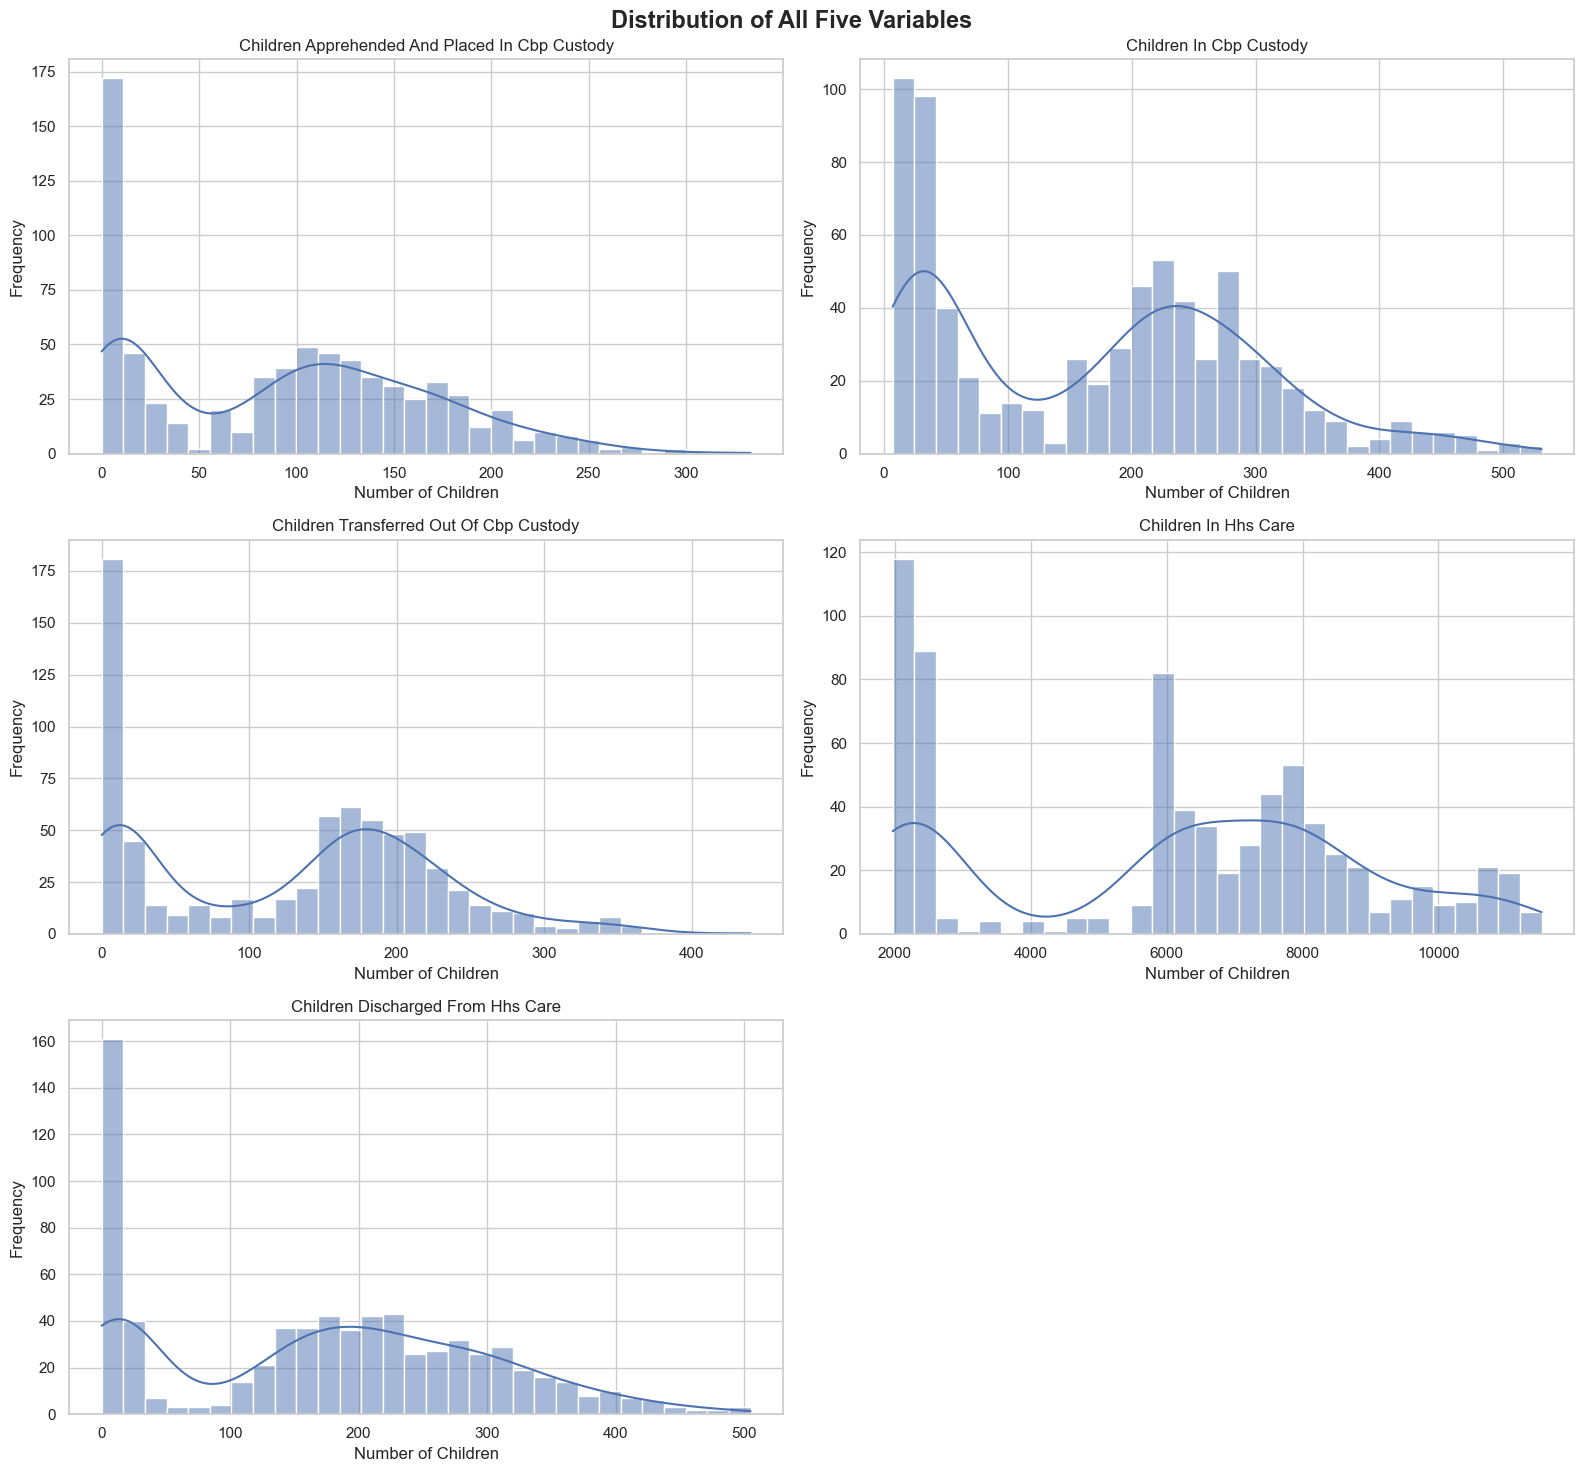

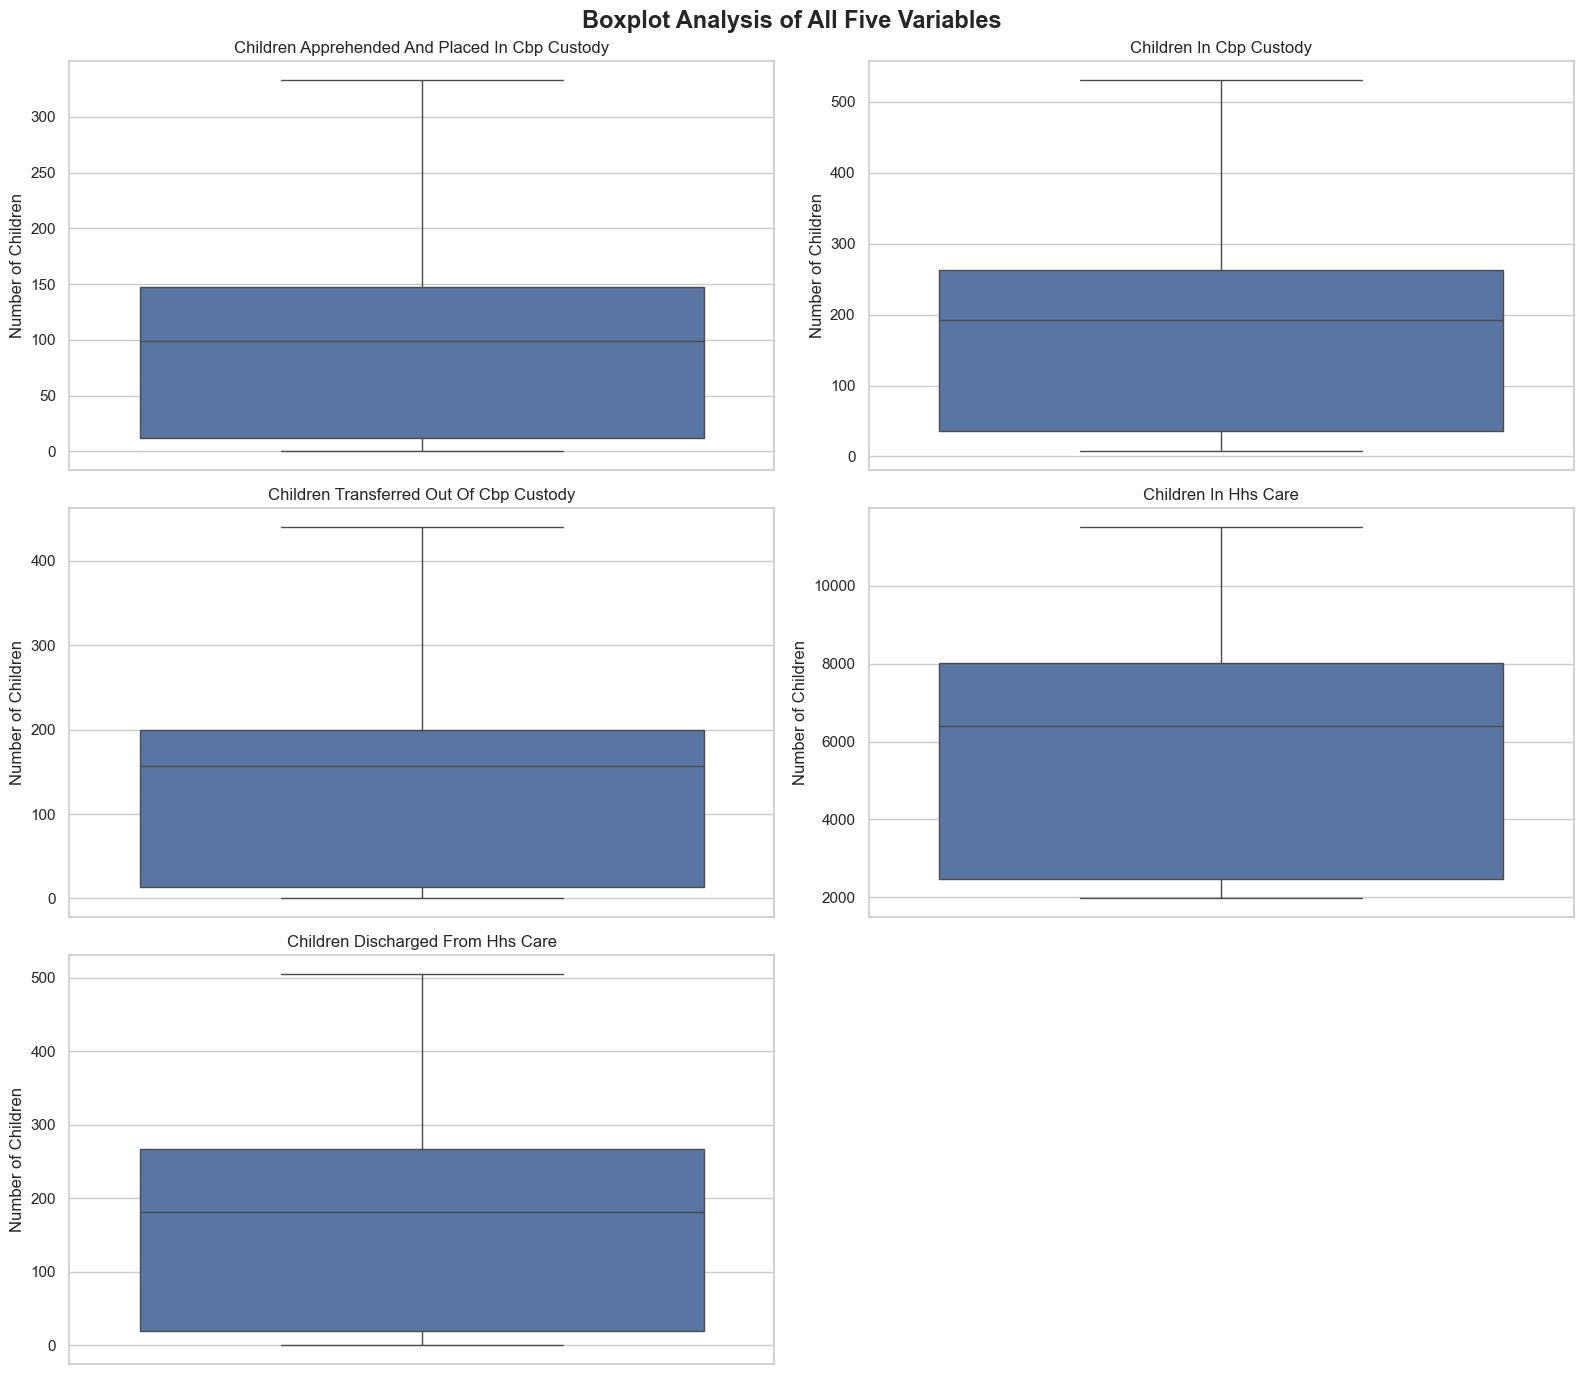

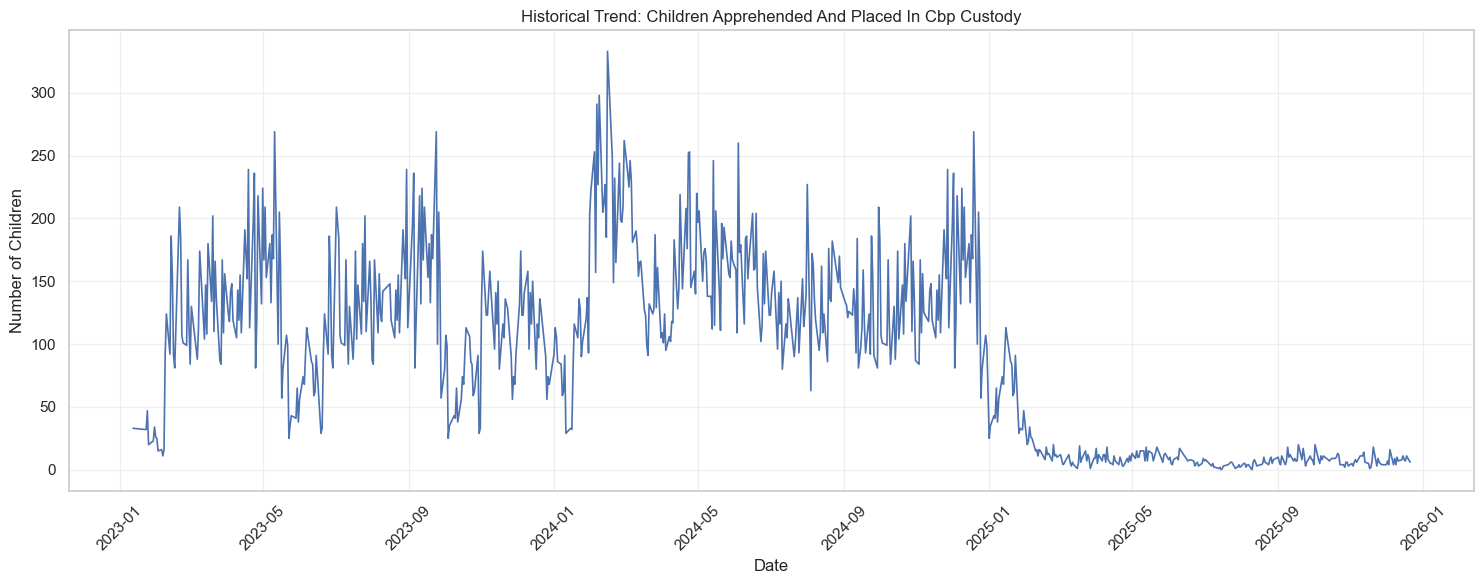

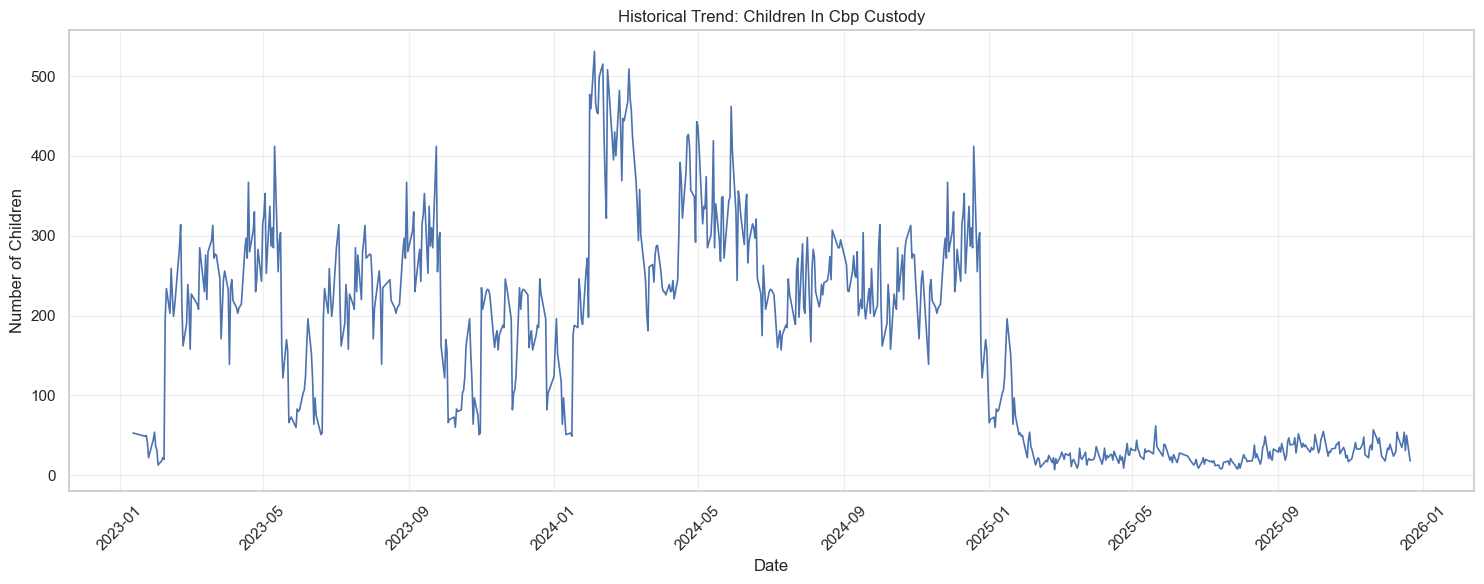

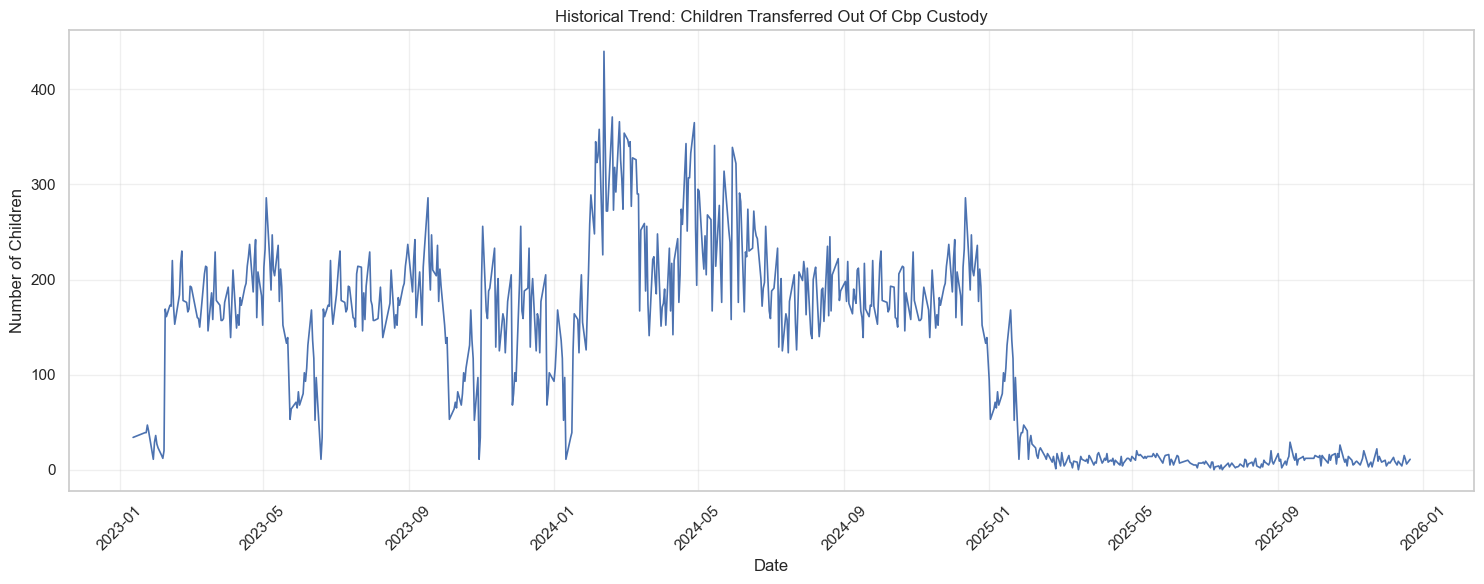

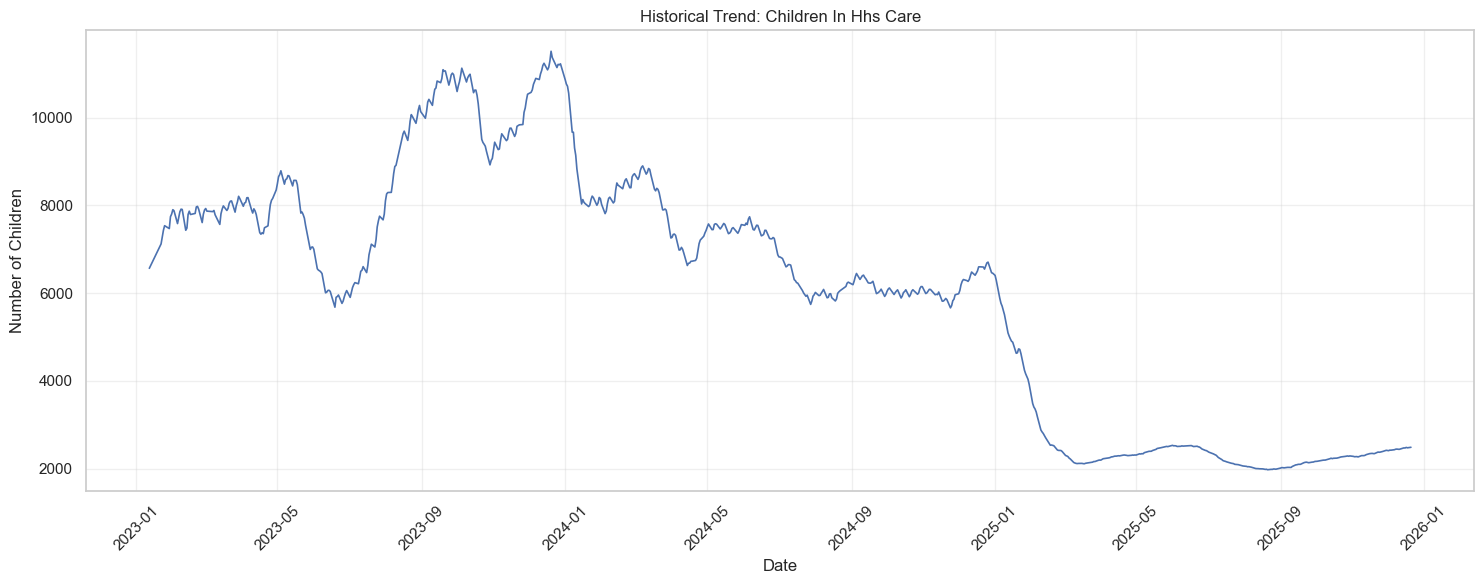

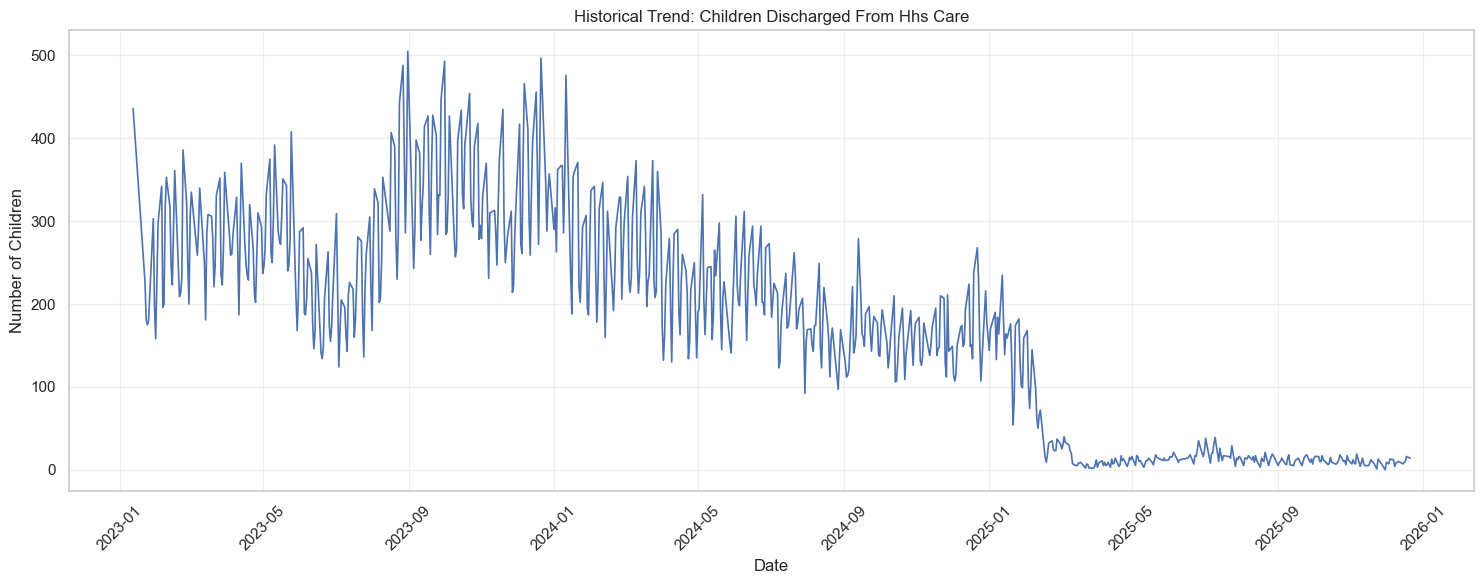

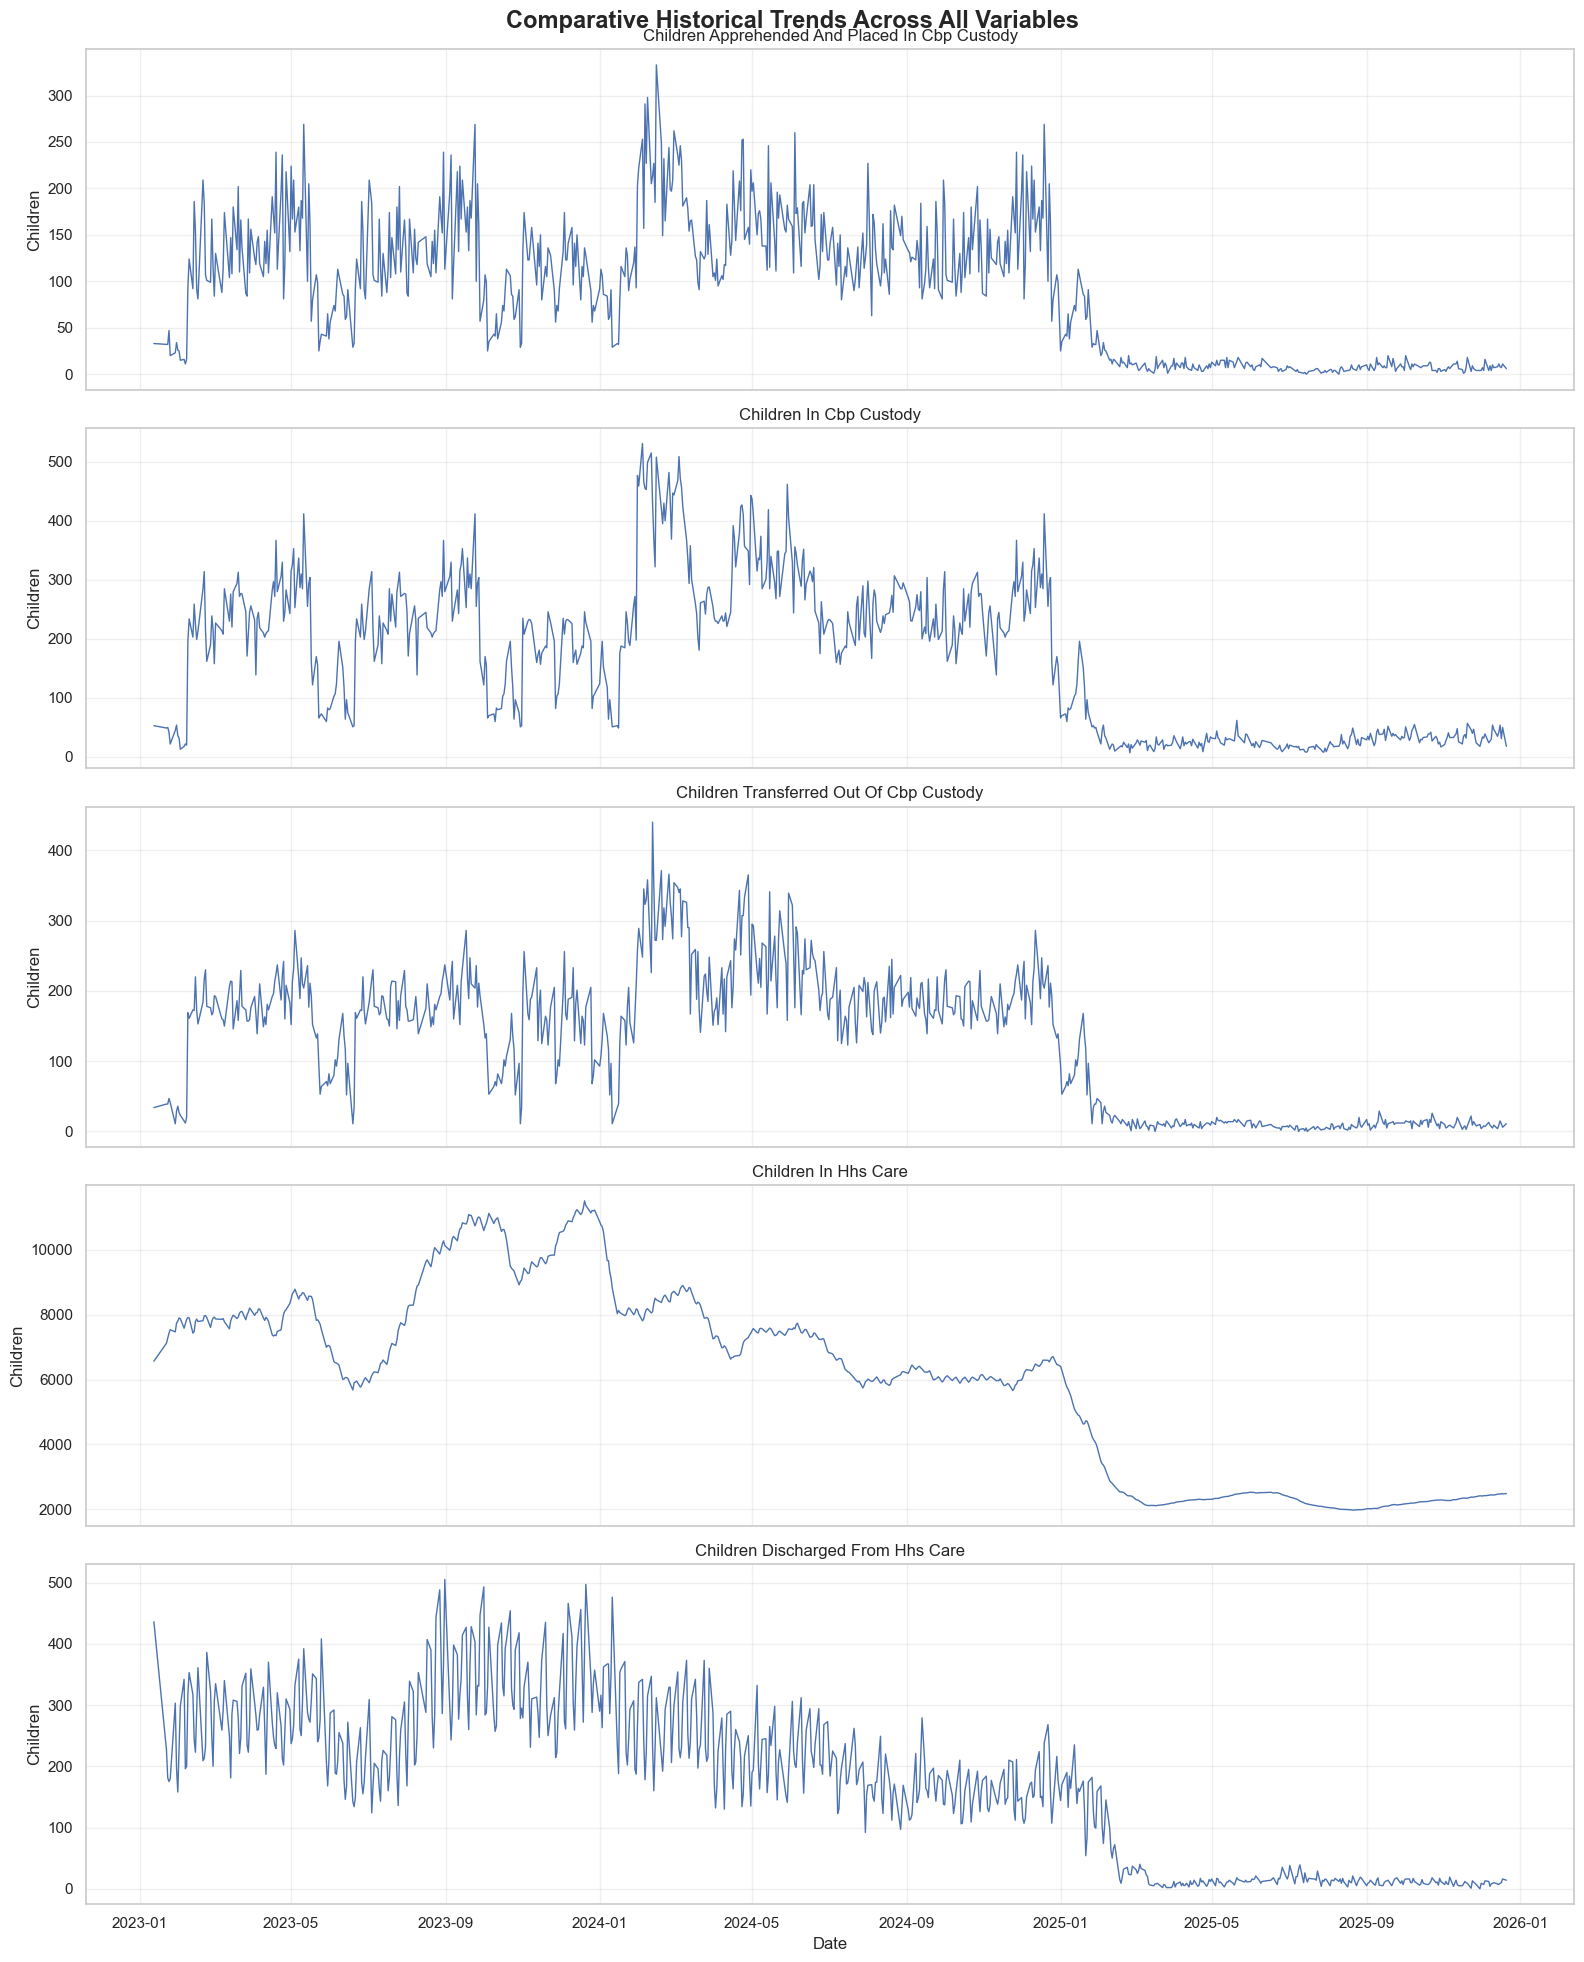


DAILY CHANGE STATISTICS
       children_apprehended_and_placed_in_cbp_custody  \
count                                          558.00   
mean                                             1.50   
std                                             43.89   
min                                           -169.00   
25%                                            -17.50   
50%                                              0.00   
75%                                             18.00   
max                                            151.00   

       children_in_cbp_custody  children_transferred_out_of_cbp_custody  \
count                   558.00                                   558.00   
mean                      0.53                                     0.73   
std                      44.86                                    39.65   
min                    -157.00                                  -137.00   
25%                     -18.00                                   -10.00   
50%        

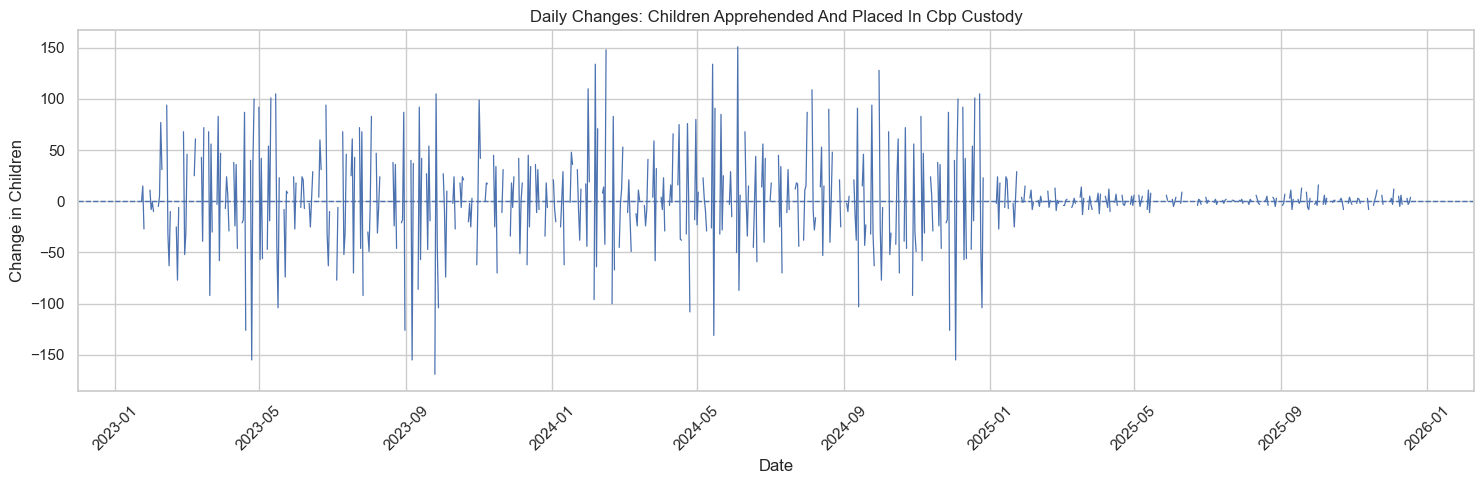

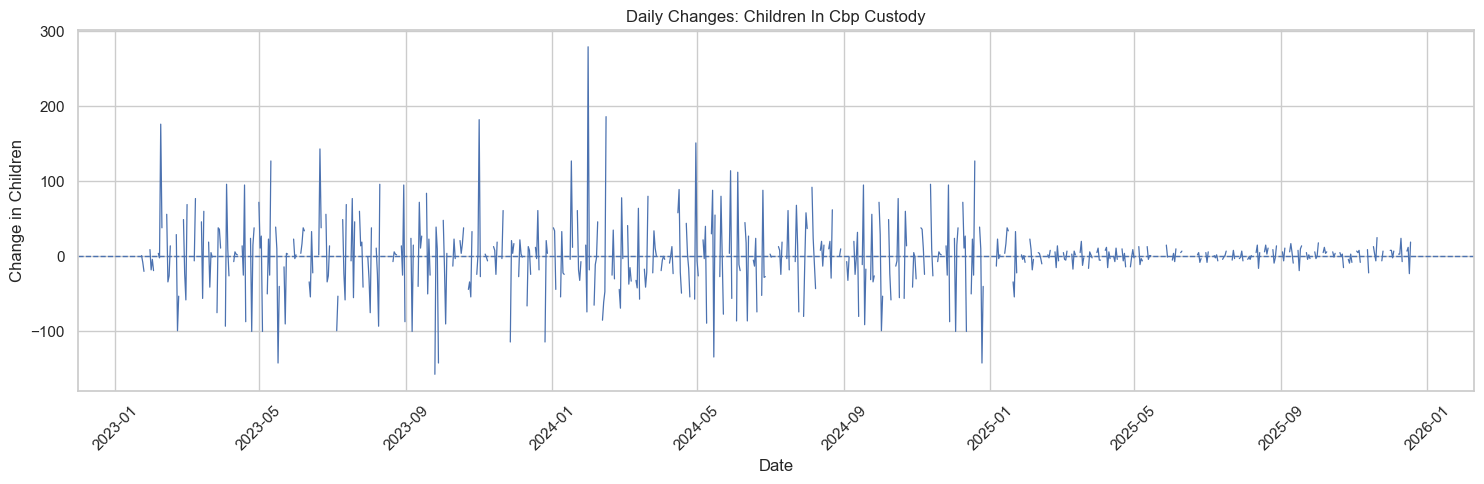

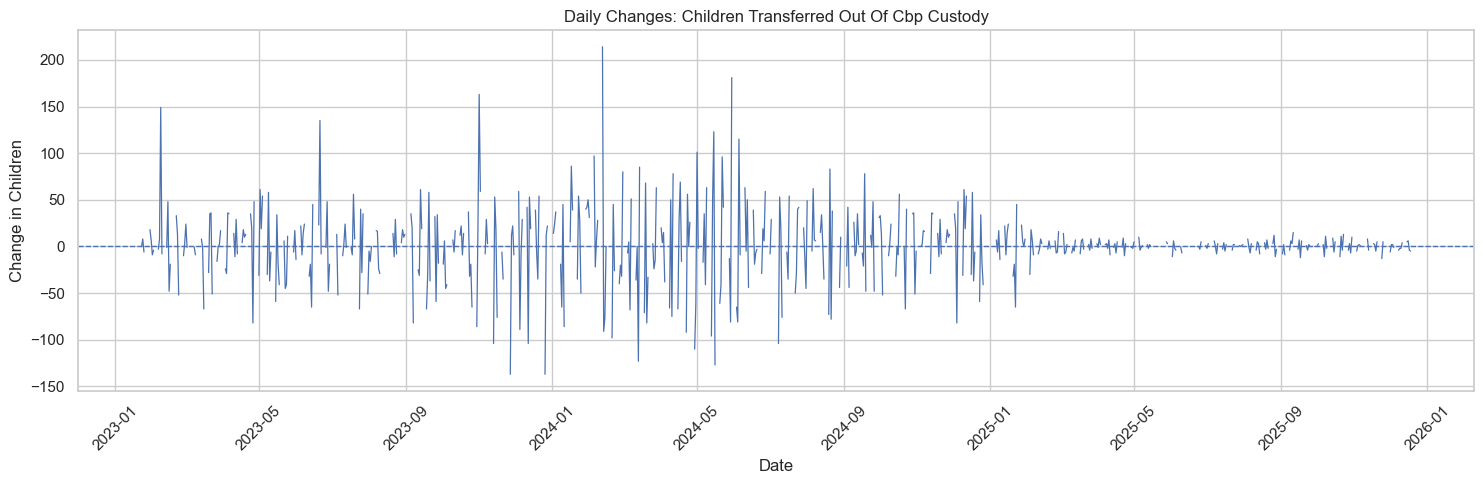

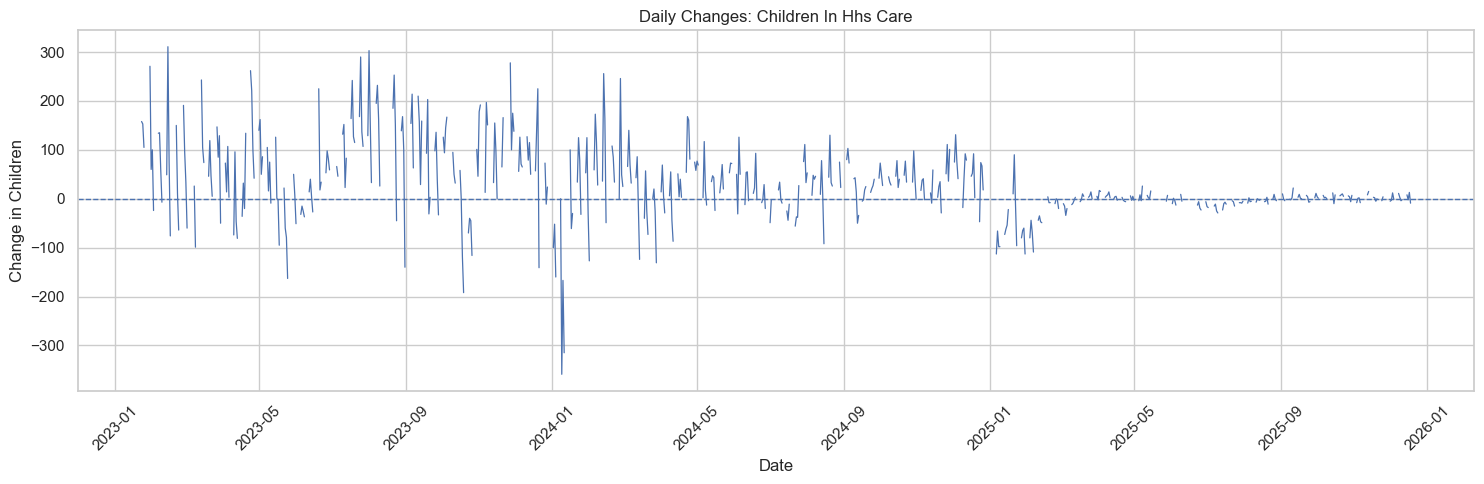

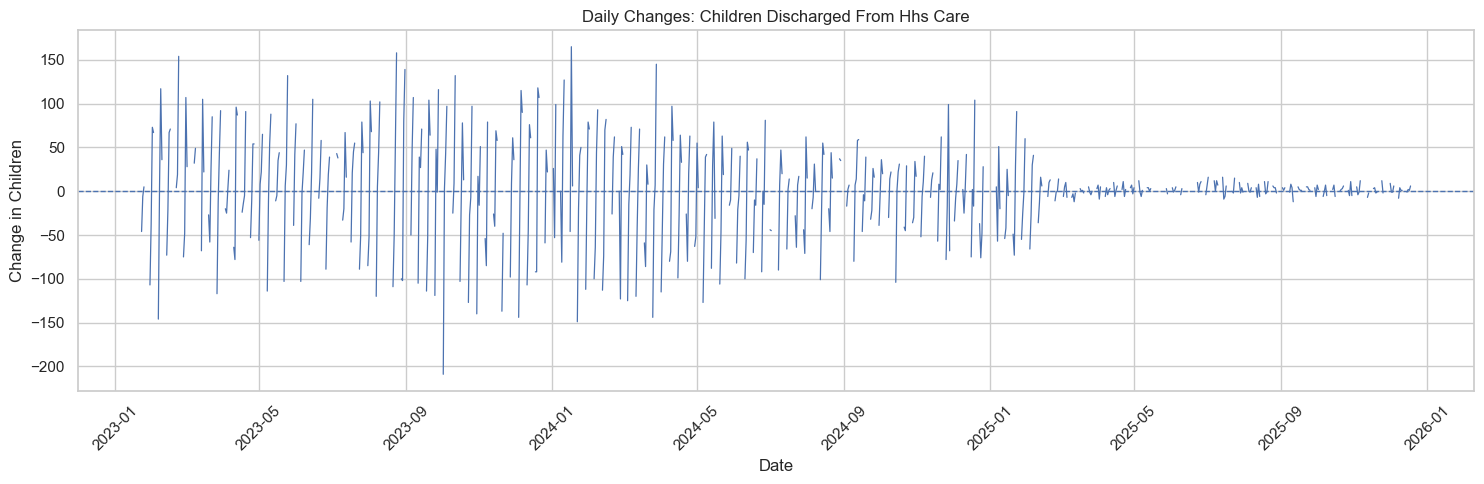

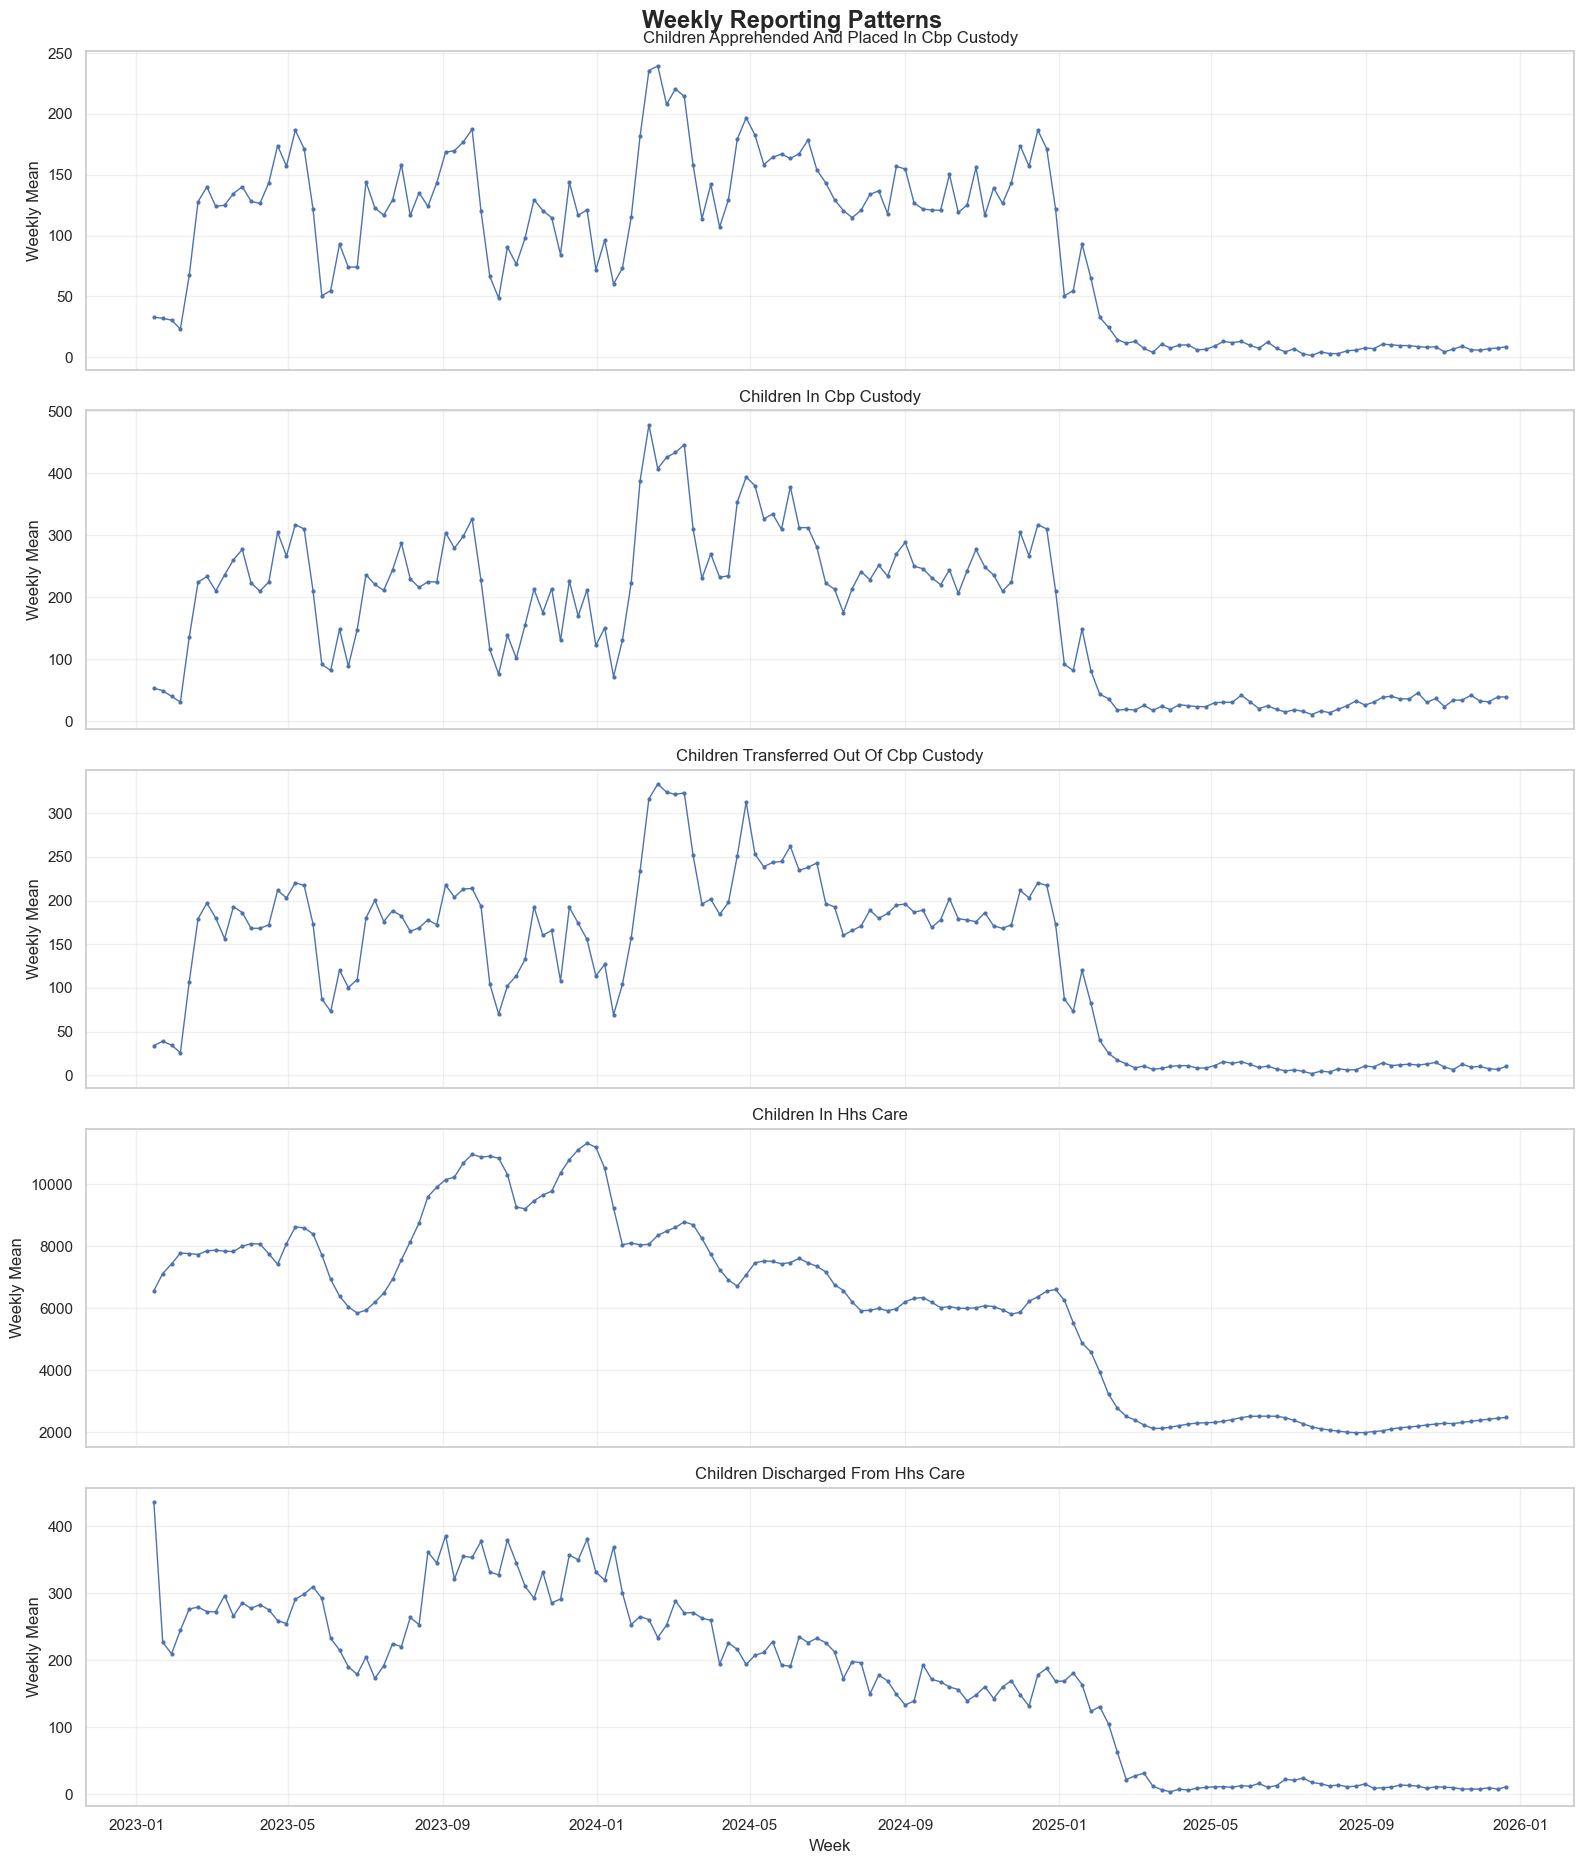

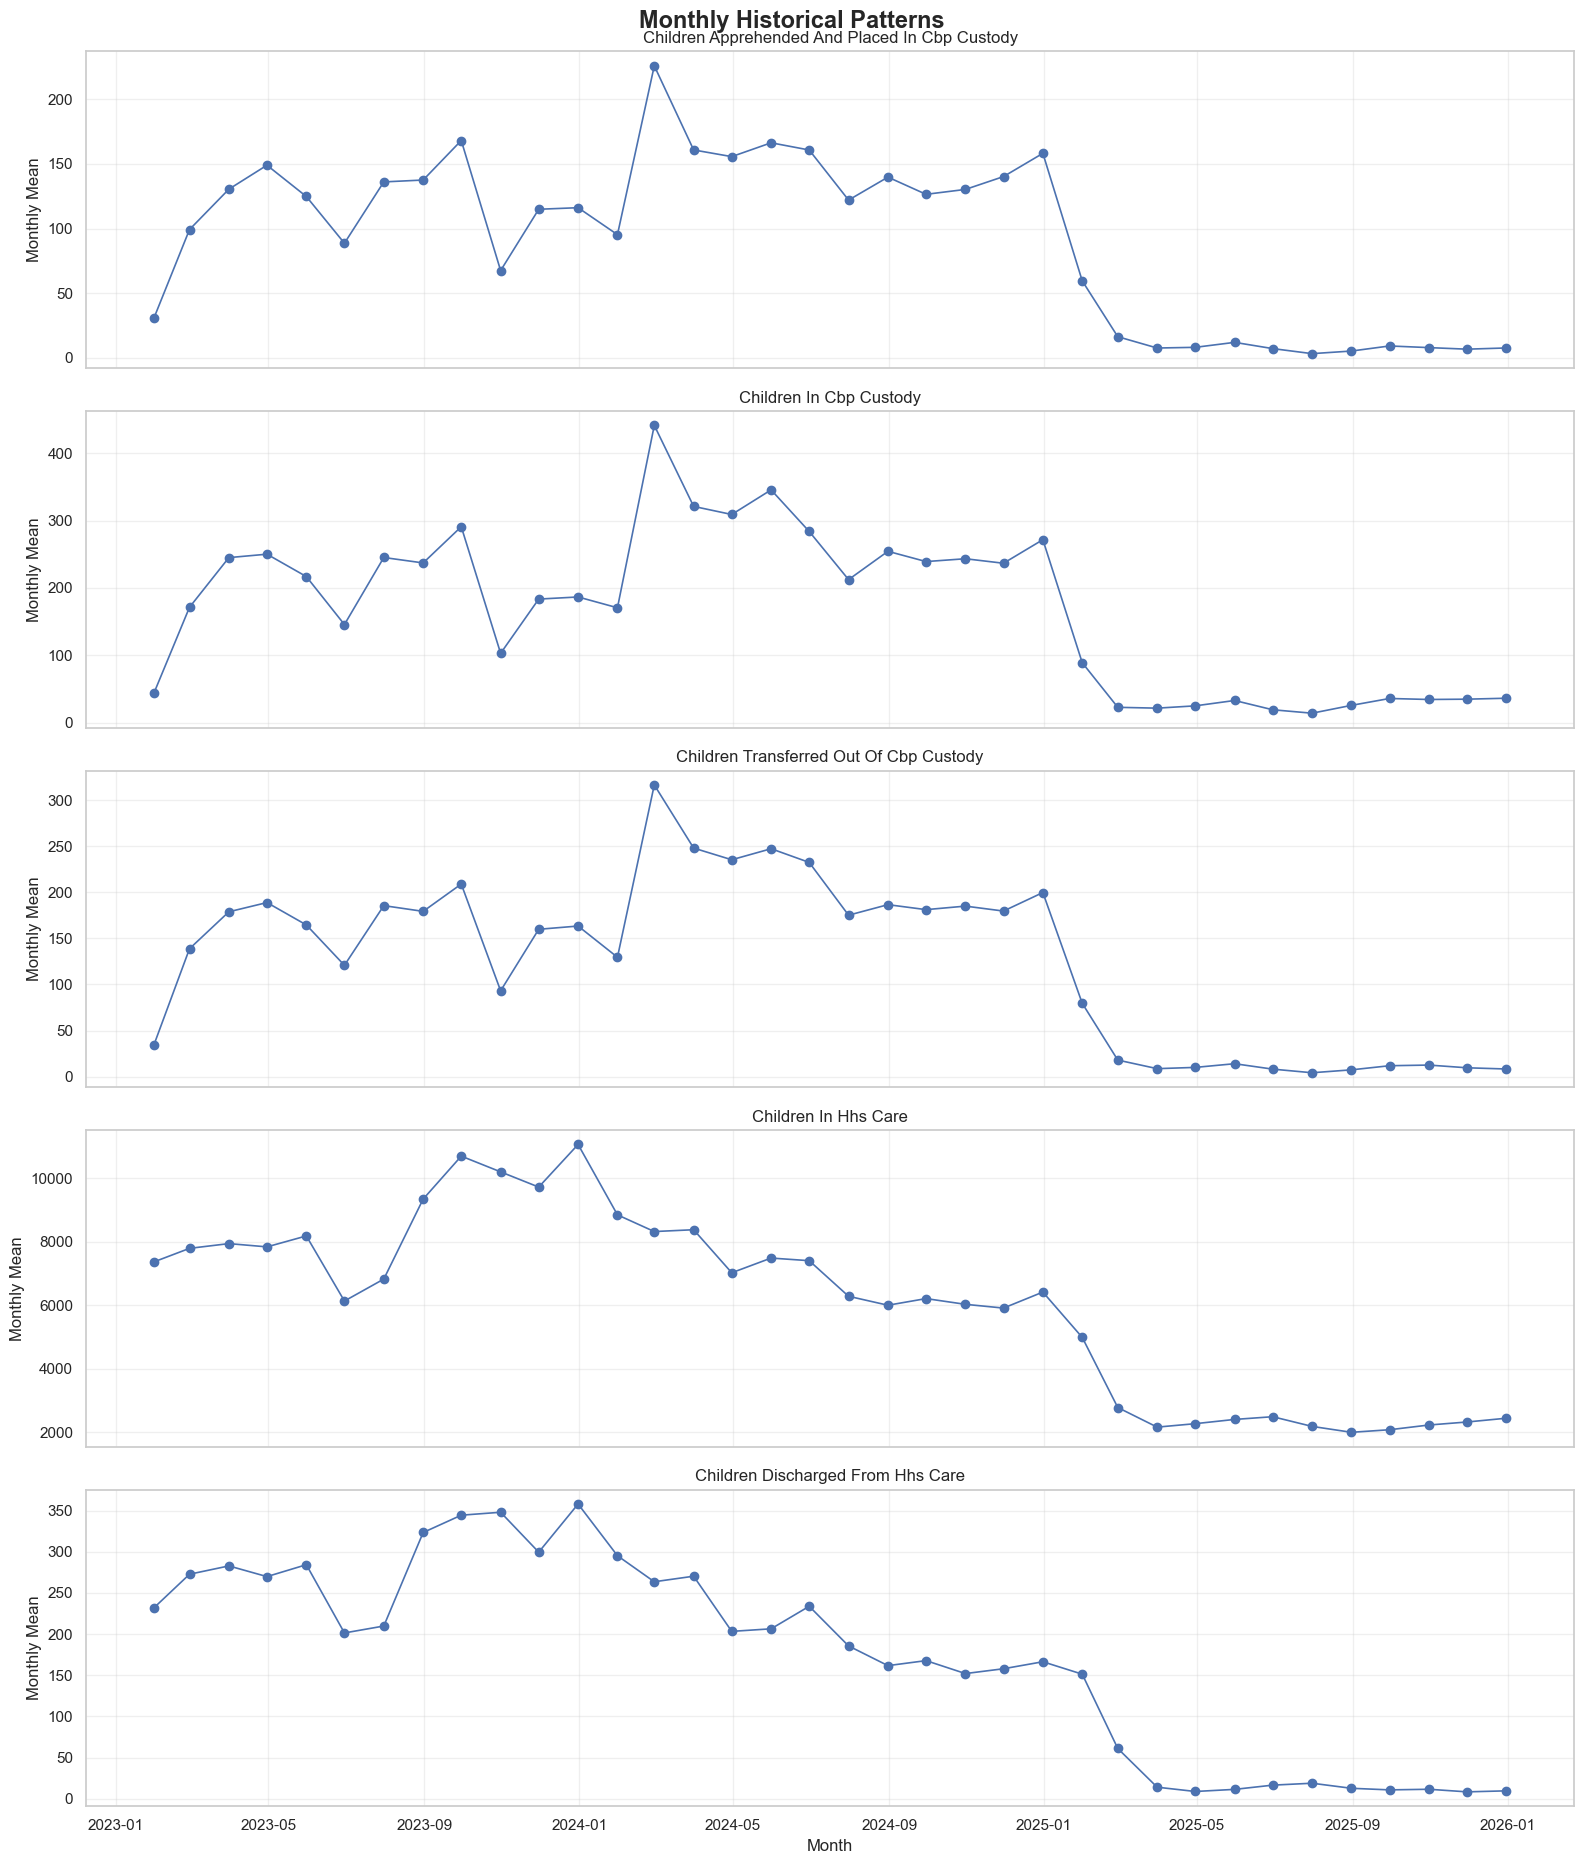

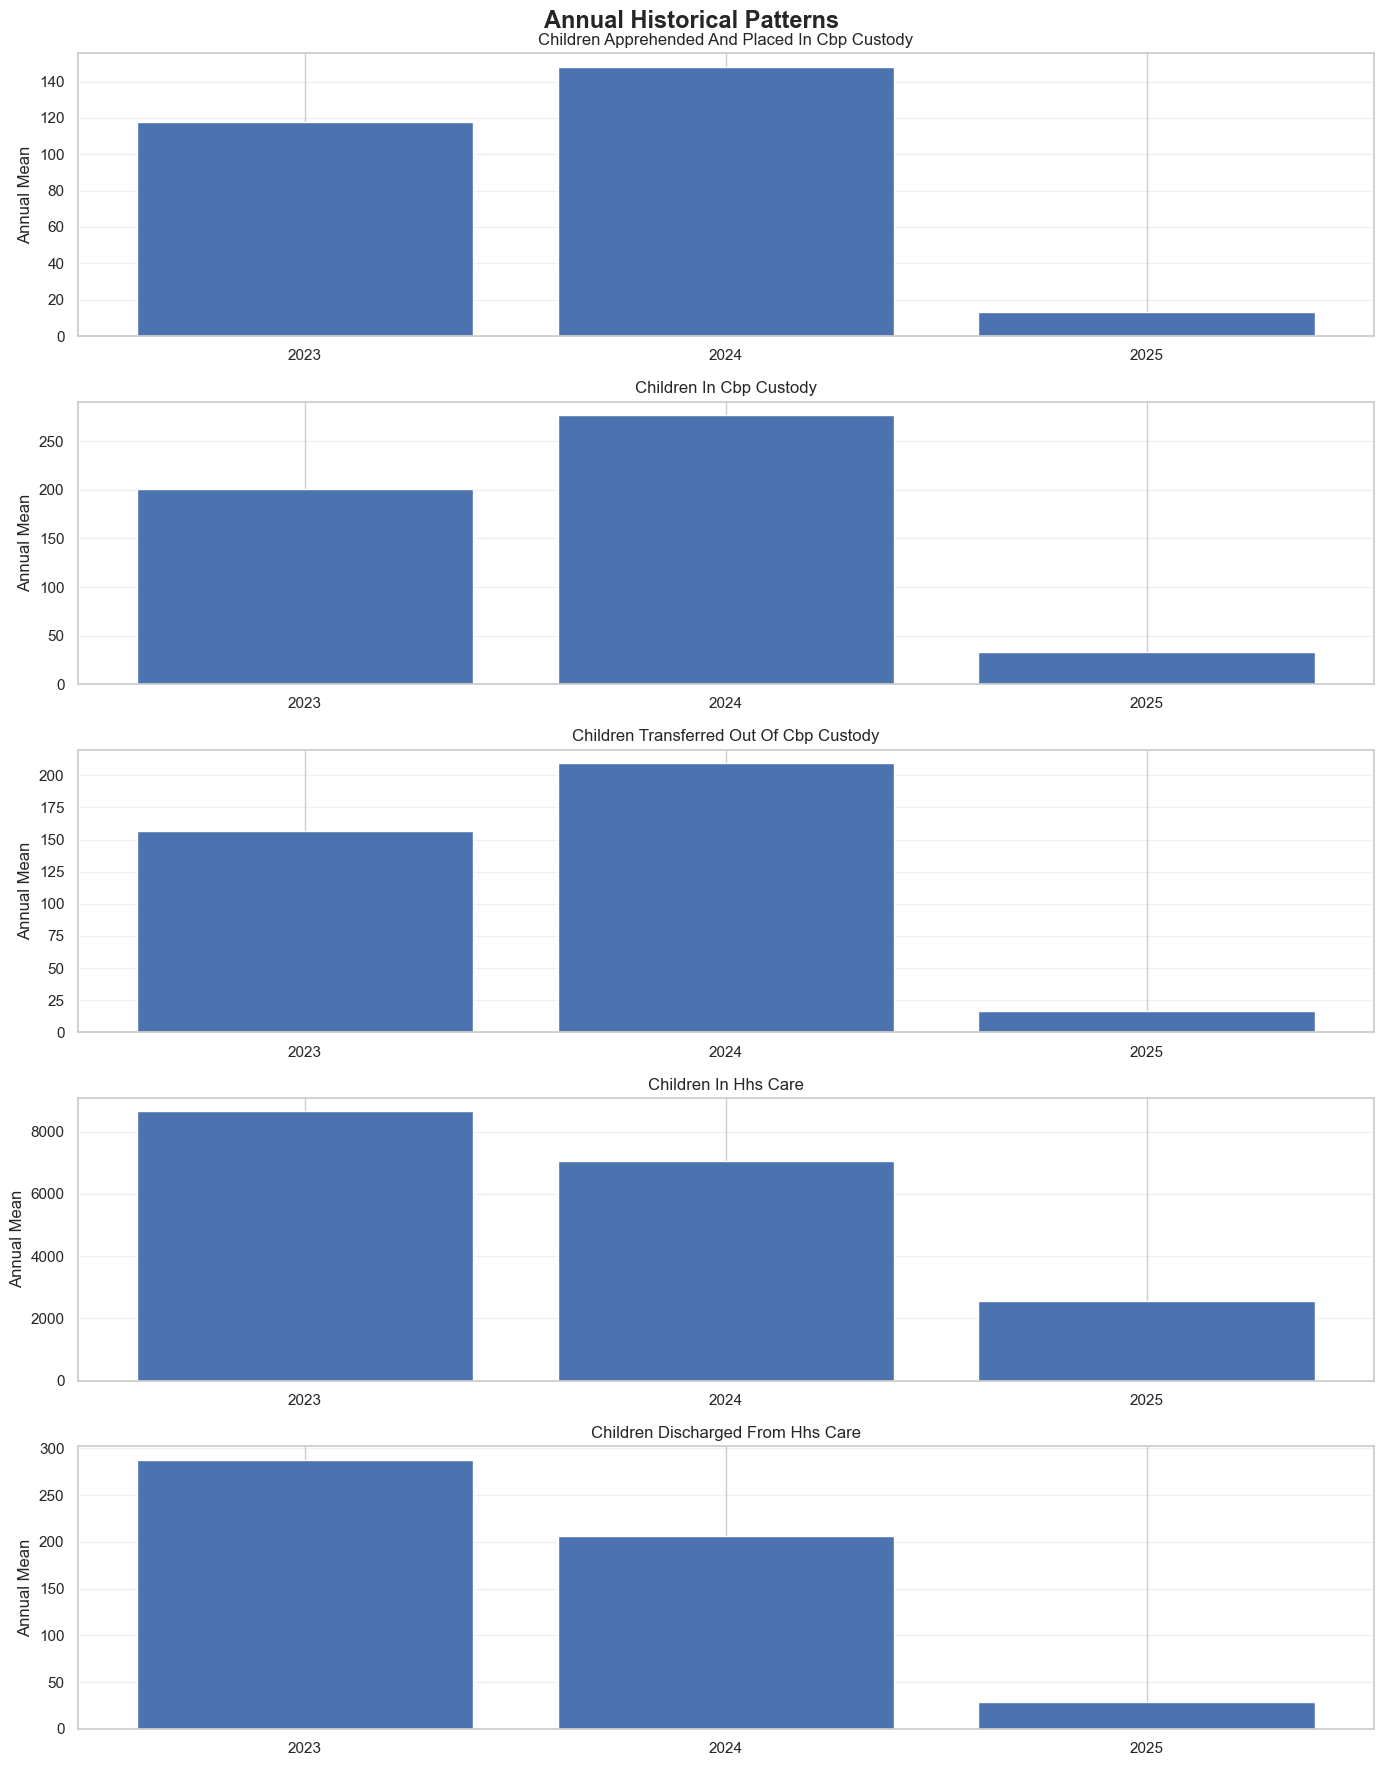

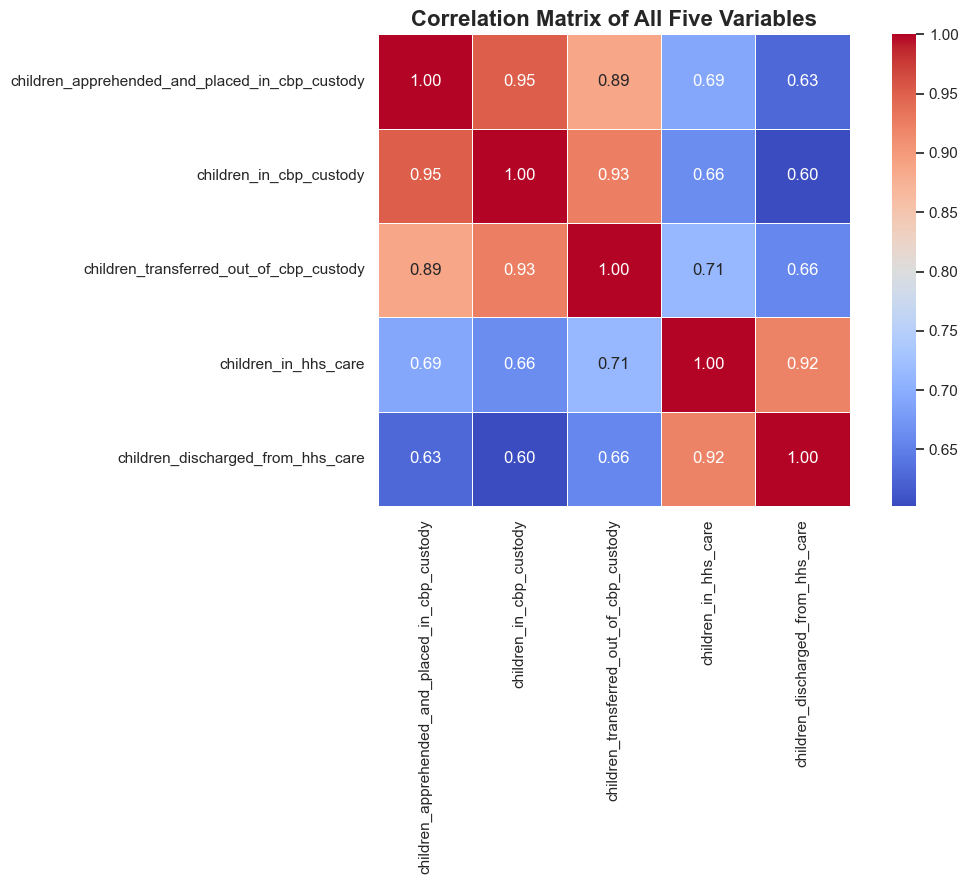

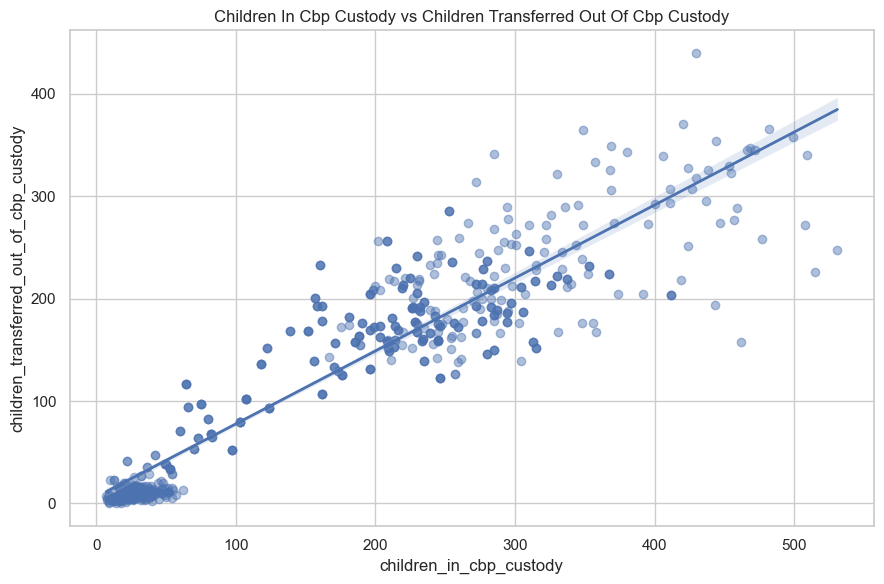

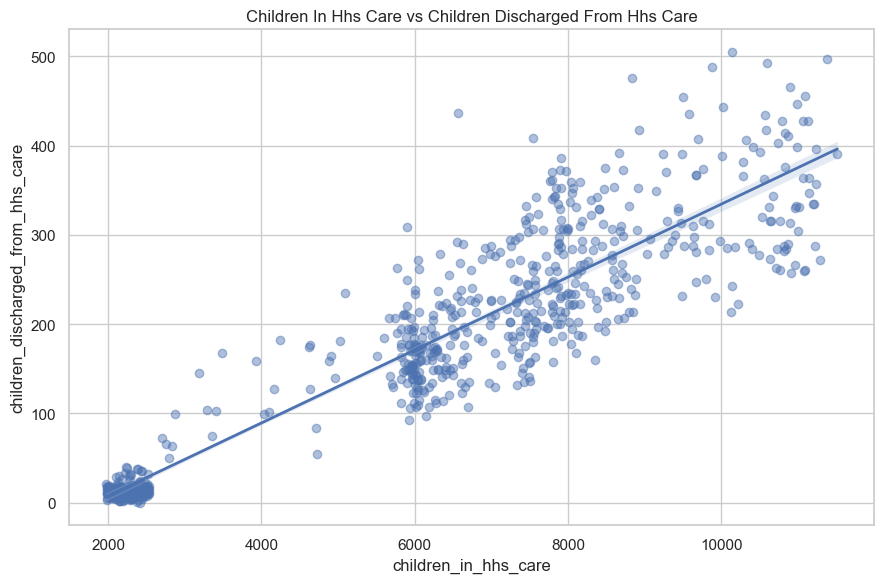

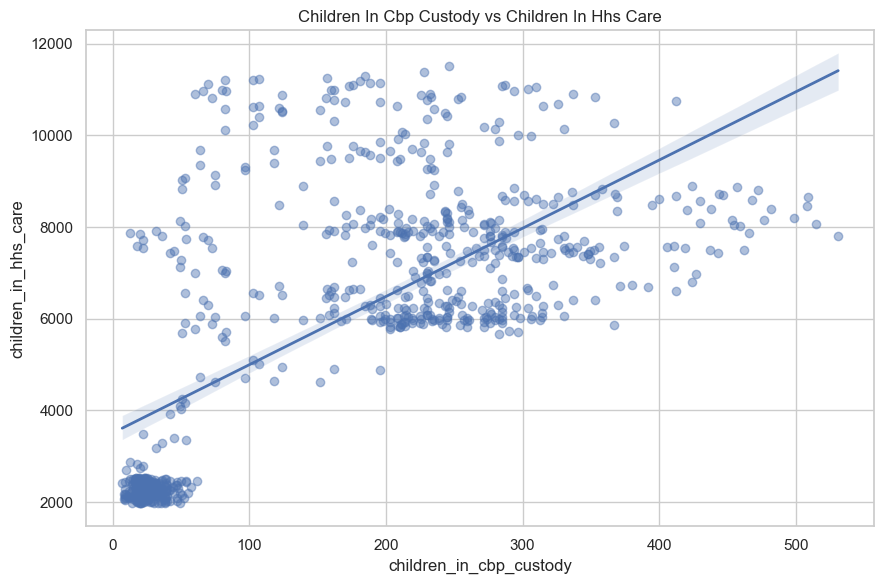

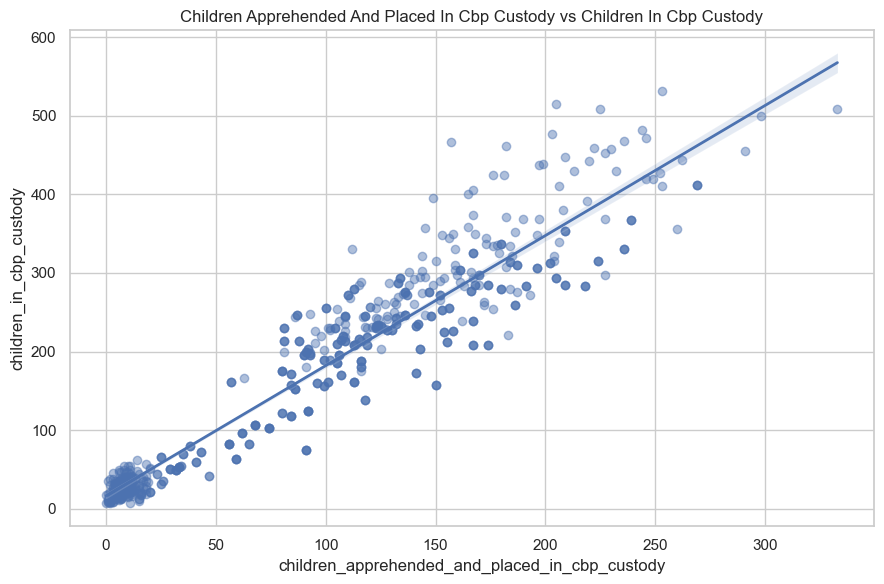

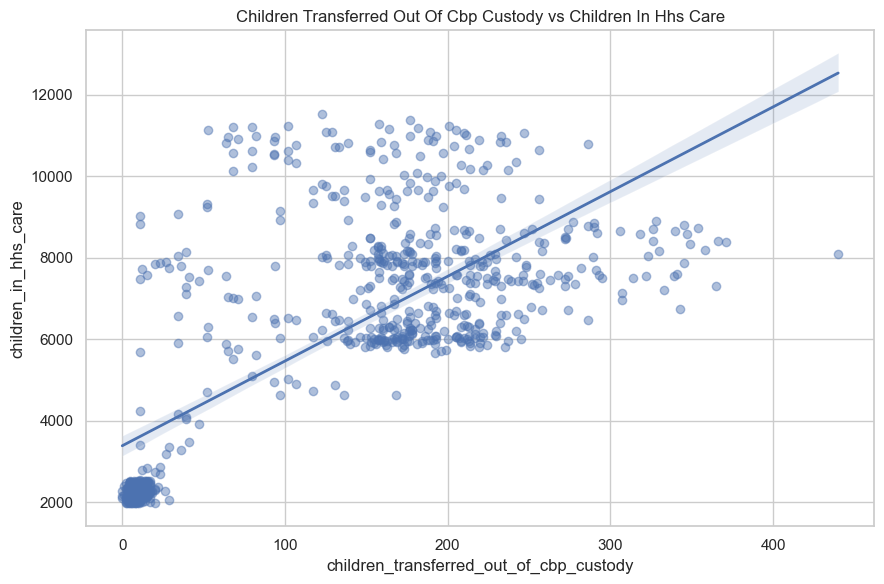


CUSTODY AND TRANSFER RELATIONSHIPS
                                    Variable_X                              Variable_Y  Correlation  Valid_Observations
                       children_in_cbp_custody children_transferred_out_of_cbp_custody        0.925                 720
                          children_in_hhs_care       children_discharged_from_hhs_care        0.921                 720
                       children_in_cbp_custody                    children_in_hhs_care        0.664                 720
children_apprehended_and_placed_in_cbp_custody                 children_in_cbp_custody        0.951                 720
       children_transferred_out_of_cbp_custody                    children_in_hhs_care        0.714                 720

HISTORICAL PEAKS AND TROUGHS
                                      Variable  Peak_Date  Peak_Value Trough_Date  Trough_Value
children_apprehended_and_placed_in_cbp_custody 2024-02-15         333  2025-07-15             0
                      

In [1]:

# ============================================================
# EXPLORATORY DATA ANALYSIS
# Project: Predictive Forecasting of Care Load & Placement Demand
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Project directory and dataset loading
# ------------------------------------------------------------

CURRENT_DIR = Path.cwd()

PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "notebooks"
    else CURRENT_DIR
)

DATASET_PATH = (
    PROJECT_ROOT / "data" / "processed" /
    "cleaned_care_data.csv"
)

OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURE_DIR = OUTPUT_DIR / "eda_figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH}"
    )

df = pd.read_csv(DATASET_PATH)

DATE_COLUMN = "date"

VARIABLES = [
    "children_apprehended_and_placed_in_cbp_custody",
    "children_in_cbp_custody",
    "children_transferred_out_of_cbp_custody",
    "children_in_hhs_care",
    "children_discharged_from_hhs_care"
]

STOCK_VARIABLES = [
    "children_in_cbp_custody",
    "children_in_hhs_care"
]

FLOW_VARIABLES = [
    "children_apprehended_and_placed_in_cbp_custody",
    "children_transferred_out_of_cbp_custody",
    "children_discharged_from_hhs_care"
]

missing_columns = [
    col for col in [DATE_COLUMN] + VARIABLES
    if col not in df.columns
]

if missing_columns:
    raise KeyError(
        f"Required columns missing: {missing_columns}"
    )

df[DATE_COLUMN] = pd.to_datetime(
    df[DATE_COLUMN], errors="coerce"
)

df = df.dropna(subset=[DATE_COLUMN]).copy()

for col in VARIABLES:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

df = df.sort_values(DATE_COLUMN).reset_index(drop=True)

if df[DATE_COLUMN].duplicated().any():
    raise ValueError(
        "Duplicate dates detected. Resolve them before analysis."
    )

# ------------------------------------------------------------
# General dataset overview
# ------------------------------------------------------------

print("=" * 70)
print("EXPLORATORY DATA ANALYSIS")
print("=" * 70)

print("Project directory:", PROJECT_ROOT)
print("Dataset:", DATASET_PATH)
print("Dataset shape:", df.shape)
print("Minimum date:", df[DATE_COLUMN].min())
print("Maximum date:", df[DATE_COLUMN].max())
print("Total observations:", len(df))

print("\nVARIABLES ANALYZED")

for variable in VARIABLES:
    print("-", variable)

print("\nDATA TYPES")
print(df[VARIABLES].dtypes)

print("\nMISSING VALUES")
print(df[VARIABLES].isna().sum())

# ------------------------------------------------------------
# Descriptive statistics
# ------------------------------------------------------------

descriptive_stats = df[VARIABLES].describe(
    percentiles=[
        0.01, 0.05, 0.10, 0.25,
        0.50, 0.75, 0.90, 0.95, 0.99
    ]
).T

descriptive_stats["Variance"] = df[VARIABLES].var()
descriptive_stats["Mode"] = df[VARIABLES].mode().iloc[0]
descriptive_stats["Missing_Count"] = df[VARIABLES].isna().sum()
descriptive_stats["Missing_Percentage"] = (
    df[VARIABLES].isna().mean() * 100
)

descriptive_stats["Skewness"] = df[VARIABLES].skew()
descriptive_stats["Kurtosis"] = df[VARIABLES].kurtosis()

descriptive_stats.to_csv(
    OUTPUT_DIR / "descriptive_statistics.csv"
)

print("\nDESCRIPTIVE STATISTICS")
print(descriptive_stats.round(2).to_string())

# ------------------------------------------------------------
# Detailed mean, median, mode and dispersion analysis
# ------------------------------------------------------------

central_tendency = pd.DataFrame(index=VARIABLES)

central_tendency["Mean"] = df[VARIABLES].mean()
central_tendency["Median"] = df[VARIABLES].median()
central_tendency["Mode"] = df[VARIABLES].mode().iloc[0]

central_tendency["Standard_Deviation"] = (
    df[VARIABLES].std()
)

central_tendency["Variance"] = df[VARIABLES].var()

central_tendency["Range"] = (
    df[VARIABLES].max() - df[VARIABLES].min()
)

central_tendency["IQR"] = (
    df[VARIABLES].quantile(0.75) -
    df[VARIABLES].quantile(0.25)
)

central_tendency.to_csv(
    OUTPUT_DIR / "central_tendency_and_dispersion.csv"
)

print("\nCENTRAL TENDENCY AND DISPERSION")
print(central_tendency.round(2).to_string())

# ------------------------------------------------------------
# Quartiles and percentiles
# ------------------------------------------------------------

percentile_values = [
    0.01, 0.05, 0.10, 0.25,
    0.50, 0.75, 0.90, 0.95, 0.99
]

percentile_analysis = df[VARIABLES].quantile(
    percentile_values
).T

percentile_analysis.columns = [
    "P01", "P05", "P10", "P25",
    "P50", "P75", "P90", "P95", "P99"
]

percentile_analysis.to_csv(
    OUTPUT_DIR / "percentile_analysis.csv"
)

print("\nQUARTILES AND PERCENTILES")
print(percentile_analysis.round(2).to_string())

# ------------------------------------------------------------
# Distribution analysis
# ------------------------------------------------------------

distribution_analysis = pd.DataFrame(index=VARIABLES)

distribution_analysis["Mean"] = df[VARIABLES].mean()
distribution_analysis["Median"] = df[VARIABLES].median()
distribution_analysis["Skewness"] = df[VARIABLES].skew()
distribution_analysis["Kurtosis"] = df[VARIABLES].kurtosis()

distribution_analysis["Distribution_Type"] = (
    distribution_analysis["Skewness"].apply(
        lambda x:
        "Right-skewed" if x > 0.5
        else "Left-skewed" if x < -0.5
        else "Approximately symmetric"
    )
)

distribution_analysis.to_csv(
    OUTPUT_DIR / "distribution_analysis.csv"
)

print("\nDISTRIBUTION ANALYSIS")
print(distribution_analysis.round(3).to_string())

# ------------------------------------------------------------
# Histograms for all five variables
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(16, 15)
)

axes = axes.flatten()

for i, variable in enumerate(VARIABLES):

    sns.histplot(
        data=df,
        x=variable,
        kde=True,
        bins=30,
        ax=axes[i]
    )

    axes[i].set_title(
        variable.replace("_", " ").title()
    )

    axes[i].set_xlabel("Number of Children")
    axes[i].set_ylabel("Frequency")

axes[-1].axis("off")

plt.suptitle(
    "Distribution of All Five Variables",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "variable_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# Boxplots for all five variables
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(16, 14)
)

axes = axes.flatten()

for i, variable in enumerate(VARIABLES):

    sns.boxplot(
        data=df,
        y=variable,
        ax=axes[i]
    )

    axes[i].set_title(
        variable.replace("_", " ").title()
    )

    axes[i].set_ylabel("Number of Children")

axes[-1].axis("off")

plt.suptitle(
    "Boxplot Analysis of All Five Variables",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "variable_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# Time-series line plots
# ------------------------------------------------------------

for variable in VARIABLES:

    fig, ax = plt.subplots(figsize=(15, 6))

    ax.plot(
        df[DATE_COLUMN],
        df[variable],
        linewidth=1.2
    )

    ax.set_title(
        f"Historical Trend: {variable.replace('_', ' ').title()}"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Number of Children")

    ax.grid(True, alpha=0.3)

    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"timeseries_{variable}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ------------------------------------------------------------
# Combined time-series comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(VARIABLES),
    1,
    figsize=(16, 20),
    sharex=True
)

for i, variable in enumerate(VARIABLES):

    axes[i].plot(
        df[DATE_COLUMN],
        df[variable],
        linewidth=1
    )

    axes[i].set_title(
        variable.replace("_", " ").title()
    )

    axes[i].set_ylabel("Children")
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel("Date")

plt.suptitle(
    "Comparative Historical Trends Across All Variables",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "combined_time_series.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# Daily changes
# ------------------------------------------------------------

date_gap = df[DATE_COLUMN].diff().dt.days

daily_changes = df[VARIABLES].diff()

# Changes are valid only when observations are one calendar day apart.
consecutive_day_mask = date_gap.eq(1)

daily_changes.loc[~consecutive_day_mask, :] = np.nan

daily_changes.insert(
    0,
    DATE_COLUMN,
    df[DATE_COLUMN]
)

daily_changes.to_csv(
    OUTPUT_DIR / "daily_changes.csv",
    index=False
)

print("\nDAILY CHANGE STATISTICS")
print(daily_changes[VARIABLES].describe().round(2))

# ------------------------------------------------------------
# Percentage changes
# ------------------------------------------------------------

percentage_changes = (
    df[VARIABLES].pct_change(fill_method=None) * 100
)

percentage_changes.loc[
    ~consecutive_day_mask, :
] = np.nan

percentage_changes.insert(
    0,
    DATE_COLUMN,
    df[DATE_COLUMN]
)

percentage_changes.to_csv(
    OUTPUT_DIR / "daily_percentage_changes.csv",
    index=False
)

print("\nDAILY PERCENTAGE CHANGE STATISTICS")
print(
    percentage_changes[VARIABLES]
    .replace([np.inf, -np.inf], np.nan)
    .describe()
    .round(2)
)

# ------------------------------------------------------------
# Daily change visualization
# ------------------------------------------------------------

for variable in VARIABLES:

    fig, ax = plt.subplots(figsize=(15, 5))

    ax.plot(
        daily_changes[DATE_COLUMN],
        daily_changes[variable],
        linewidth=0.9
    )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        f"Daily Changes: {variable.replace('_', ' ').title()}"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Change in Children")

    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"daily_changes_{variable}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ------------------------------------------------------------
# Weekly patterns
# ------------------------------------------------------------

weekly_data = (
    df.set_index(DATE_COLUMN)[VARIABLES]
    .resample("W")
)

weekly_mean = weekly_data.mean()
weekly_count = weekly_data.count()

weekly_mean.to_csv(
    OUTPUT_DIR / "weekly_patterns.csv"
)

weekly_count.to_csv(
    OUTPUT_DIR / "weekly_observation_counts.csv"
)

fig, axes = plt.subplots(
    len(VARIABLES),
    1,
    figsize=(16, 19),
    sharex=True
)

for i, variable in enumerate(VARIABLES):

    axes[i].plot(
        weekly_mean.index,
        weekly_mean[variable],
        marker="o",
        markersize=2,
        linewidth=1
    )

    axes[i].set_title(
        variable.replace("_", " ").title()
    )

    axes[i].set_ylabel("Weekly Mean")
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel("Week")

plt.suptitle(
    "Weekly Reporting Patterns",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "weekly_patterns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# Monthly patterns
# ------------------------------------------------------------

monthly_mean = (
    df.set_index(DATE_COLUMN)[VARIABLES]
    .resample("ME")
    .mean()
)

monthly_sum = (
    df.set_index(DATE_COLUMN)[FLOW_VARIABLES]
    .resample("ME")
    .sum(min_count=1)
)

monthly_count = (
    df.set_index(DATE_COLUMN)[VARIABLES]
    .resample("ME")
    .count()
)

monthly_mean.to_csv(
    OUTPUT_DIR / "monthly_mean_patterns.csv"
)

monthly_sum.to_csv(
    OUTPUT_DIR / "monthly_observed_flow_sums.csv"
)

monthly_count.to_csv(
    OUTPUT_DIR / "monthly_observation_counts.csv"
)

fig, axes = plt.subplots(
    len(VARIABLES),
    1,
    figsize=(16, 19),
    sharex=True
)

for i, variable in enumerate(VARIABLES):

    axes[i].plot(
        monthly_mean.index,
        monthly_mean[variable],
        marker="o",
        linewidth=1.2
    )

    axes[i].set_title(
        variable.replace("_", " ").title()
    )

    axes[i].set_ylabel("Monthly Mean")
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel("Month")

plt.suptitle(
    "Monthly Historical Patterns",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "monthly_patterns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# Annual patterns
# ------------------------------------------------------------

annual_mean = (
    df.set_index(DATE_COLUMN)[VARIABLES]
    .resample("YE")
    .mean()
)

annual_sum = (
    df.set_index(DATE_COLUMN)[FLOW_VARIABLES]
    .resample("YE")
    .sum(min_count=1)
)

annual_count = (
    df.set_index(DATE_COLUMN)[VARIABLES]
    .resample("YE")
    .count()
)

annual_mean.to_csv(
    OUTPUT_DIR / "annual_mean_patterns.csv"
)

annual_sum.to_csv(
    OUTPUT_DIR / "annual_observed_flow_sums.csv"
)

annual_count.to_csv(
    OUTPUT_DIR / "annual_observation_counts.csv"
)

fig, axes = plt.subplots(
    len(VARIABLES),
    1,
    figsize=(14, 18)
)

for i, variable in enumerate(VARIABLES):

    axes[i].bar(
        annual_mean.index.year.astype(str),
        annual_mean[variable]
    )

    axes[i].set_title(
        variable.replace("_", " ").title()
    )

    axes[i].set_ylabel("Annual Mean")

    axes[i].grid(
        axis="y",
        alpha=0.3
    )

plt.suptitle(
    "Annual Historical Patterns",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "annual_patterns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# Variable correlation analysis
# ------------------------------------------------------------

correlation_matrix = df[VARIABLES].corr(
    method="pearson"
)

correlation_matrix.to_csv(
    OUTPUT_DIR / "variable_correlations.csv"
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True
)

plt.title(
    "Correlation Matrix of All Five Variables",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# Custody and transfer relationships
# ------------------------------------------------------------

custody_relationships = [
    ("children_in_cbp_custody",
     "children_transferred_out_of_cbp_custody"),

    ("children_in_hhs_care",
     "children_discharged_from_hhs_care"),

    ("children_in_cbp_custody",
     "children_in_hhs_care"),

    ("children_apprehended_and_placed_in_cbp_custody",
     "children_in_cbp_custody"),

    ("children_transferred_out_of_cbp_custody",
     "children_in_hhs_care")
]

relationship_results = []

for x_variable, y_variable in custody_relationships:

    valid_data = df[
        [x_variable, y_variable]
    ].dropna()

    correlation = valid_data[
        x_variable
    ].corr(valid_data[y_variable])

    relationship_results.append({
        "Variable_X": x_variable,
        "Variable_Y": y_variable,
        "Correlation": correlation,
        "Valid_Observations": len(valid_data)
    })

    fig, ax = plt.subplots(figsize=(9, 6))

    sns.regplot(
        data=valid_data,
        x=x_variable,
        y=y_variable,
        scatter_kws={"alpha": 0.45},
        line_kws={"linewidth": 2},
        ax=ax
    )

    ax.set_title(
        f"{x_variable.replace('_', ' ').title()} vs "
        f"{y_variable.replace('_', ' ').title()}"
    )

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR /
        f"relationship_{x_variable}_vs_{y_variable}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

relationship_df = pd.DataFrame(
    relationship_results
)

relationship_df.to_csv(
    OUTPUT_DIR / "custody_transfer_relationships.csv",
    index=False
)

print("\nCUSTODY AND TRANSFER RELATIONSHIPS")
print(relationship_df.round(3).to_string(index=False))

# ------------------------------------------------------------
# Historical peaks and troughs
# ------------------------------------------------------------

extreme_results = []

for variable in VARIABLES:

    valid_data = df[
        [DATE_COLUMN, variable]
    ].dropna()

    if valid_data.empty:
        continue

    maximum_row = valid_data.loc[
        valid_data[variable].idxmax()
    ]

    minimum_row = valid_data.loc[
        valid_data[variable].idxmin()
    ]

    extreme_results.append({
        "Variable": variable,
        "Peak_Date": maximum_row[DATE_COLUMN],
        "Peak_Value": maximum_row[variable],
        "Trough_Date": minimum_row[DATE_COLUMN],
        "Trough_Value": minimum_row[variable]
    })

extreme_analysis = pd.DataFrame(extreme_results)

extreme_analysis.to_csv(
    OUTPUT_DIR / "historical_peaks_and_troughs.csv",
    index=False
)

print("\nHISTORICAL PEAKS AND TROUGHS")
print(extreme_analysis.to_string(index=False))

# ------------------------------------------------------------
# Historical surge periods
# ------------------------------------------------------------

surge_results = []

for variable in VARIABLES:

    changes = daily_changes[
        [DATE_COLUMN, variable]
    ].dropna()

    if changes.empty:
        continue

    largest_increases = changes.nlargest(
        5,
        variable
    )

    for _, row in largest_increases.iterrows():

        surge_results.append({
            "Variable": variable,
            "Date": row[DATE_COLUMN],
            "Daily_Increase": row[variable],
            "Surge_Type": "Largest positive consecutive-day change"
        })

surge_analysis = pd.DataFrame(surge_results)

surge_analysis.to_csv(
    OUTPUT_DIR / "historical_surge_periods.csv",
    index=False
)

print("\nHISTORICAL SURGE PERIODS")
print(surge_analysis.to_string(index=False))

# ------------------------------------------------------------
# Trend comparison across all five variables
# ------------------------------------------------------------

trend_results = []

for variable in VARIABLES:

    valid_data = df[
        [DATE_COLUMN, variable]
    ].dropna()

    if len(valid_data) >= 2:

        x = (
            valid_data[DATE_COLUMN] -
            valid_data[DATE_COLUMN].min()
        ).dt.days.to_numpy()

        y = valid_data[variable].to_numpy()

        slope, intercept = np.polyfit(
            x,
            y,
            1
        )

        fitted = slope * x + intercept

        ss_res = np.sum((y - fitted) ** 2)
        ss_tot = np.sum((y - y.mean()) ** 2)

        r_squared = (
            1 - ss_res / ss_tot
            if ss_tot != 0 else np.nan
        )

    else:

        slope = np.nan
        intercept = np.nan
        r_squared = np.nan

    trend_results.append({
        "Variable": variable,
        "Trend_Slope_Per_Calendar_Day": slope,
        "Trend_Slope_Per_30_Days": slope * 30,
        "Trend_R_Squared": r_squared,
        "Overall_Trend": (
            "Increasing" if slope > 0
            else "Decreasing" if slope < 0
            else "No change or unavailable"
        )
    })

trend_comparison = pd.DataFrame(
    trend_results
)

trend_comparison.to_csv(
    OUTPUT_DIR / "trend_comparison.csv",
    index=False
)

print("\nTREND COMPARISON")
print(trend_comparison.round(4).to_string(index=False))

# ------------------------------------------------------------
# Generate analytical findings
# ------------------------------------------------------------

findings = []

findings.append(
    "EXPLORATORY DATA ANALYSIS - ANALYTICAL FINDINGS"
)

findings.append("=" * 65)

findings.append(
    f"Dataset contains {len(df)} observed records."
)

findings.append(
    f"Observation period: {df[DATE_COLUMN].min().date()} "
    f"to {df[DATE_COLUMN].max().date()}."
)

findings.append(
    "All five variables were examined using descriptive "
    "statistics, distributions, historical trends and correlations."
)

findings.append("\nDESCRIPTIVE FINDINGS")

for variable in VARIABLES:

    findings.append(
        f"{variable}: Mean={df[variable].mean():.2f}, "
        f"Median={df[variable].median():.2f}, "
        f"Standard Deviation={df[variable].std():.2f}, "
        f"Minimum={df[variable].min()}, "
        f"Maximum={df[variable].max()}."
    )

findings.append("\nDISTRIBUTION FINDINGS")

for variable in VARIABLES:

    skewness = df[variable].skew()

    if pd.isna(skewness):
        distribution = "Undetermined"
    elif skewness > 0.5:
        distribution = "Right-skewed"
    elif skewness < -0.5:
        distribution = "Left-skewed"
    else:
        distribution = "Approximately symmetric"

    findings.append(
        f"{variable}: {distribution}; "
        f"skewness={skewness:.3f}."
    )

findings.append("\nTREND FINDINGS")

for _, row in trend_comparison.iterrows():

    findings.append(
        f"{row['Variable']}: {row['Overall_Trend']}; "
        f"estimated daily slope="
        f"{row['Trend_Slope_Per_Calendar_Day']:.4f}; "
        f"R-squared={row['Trend_R_Squared']:.4f}."
    )

findings.append("\nCORRELATION FINDINGS")

for i in range(len(VARIABLES)):

    for j in range(i + 1, len(VARIABLES)):

        variable_1 = VARIABLES[i]
        variable_2 = VARIABLES[j]

        correlation = correlation_matrix.loc[
            variable_1,
            variable_2
        ]

        findings.append(
            f"{variable_1} and {variable_2}: "
            f"Pearson correlation={correlation:.3f}."
        )

findings.append("\nHISTORICAL EXTREMES")

for _, row in extreme_analysis.iterrows():

    findings.append(
        f"{row['Variable']}: Peak={row['Peak_Value']} "
        f"on {row['Peak_Date'].date()}; "
        f"Trough={row['Trough_Value']} "
        f"on {row['Trough_Date'].date()}."
    )

findings.append("\nMETHODOLOGICAL LIMITATIONS")

findings.append(
    "Daily changes and percentage changes are calculated "
    "only between consecutive calendar-day observations."
)

findings.append(
    "Weekly, monthly and annual summaries are based on available "
    "observations. Period totals must not be interpreted as "
    "complete totals when reporting dates are missing."
)

findings.append(
    "Correlations indicate association, not causation."
)

findings.append(
    "Historical peaks and surges describe observed data and "
    "do not independently establish future demand."
)

findings.append(
    "Custody stock variables are distinguished from flow variables."
)

findings.append(
    "Missing observations are not automatically replaced with zero."
)

findings.append(
    "Linear trend estimates are descriptive and do not establish "
    "a forecasting model."
)

findings_text = "\n".join(findings)

with open(
    OUTPUT_DIR / "eda_analytical_findings.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write(findings_text)

print("\n" + "=" * 70)
print("ANALYTICAL FINDINGS")
print("=" * 70)

print(findings_text)

# ------------------------------------------------------------
# Final output verification
# ------------------------------------------------------------

expected_files = [
    "descriptive_statistics.csv",
    "central_tendency_and_dispersion.csv",
    "percentile_analysis.csv",
    "distribution_analysis.csv",
    "daily_changes.csv",
    "daily_percentage_changes.csv",
    "weekly_patterns.csv",
    "weekly_observation_counts.csv",
    "monthly_mean_patterns.csv",
    "monthly_observed_flow_sums.csv",
    "monthly_observation_counts.csv",
    "annual_mean_patterns.csv",
    "annual_observed_flow_sums.csv",
    "annual_observation_counts.csv",
    "variable_correlations.csv",
    "custody_transfer_relationships.csv",
    "historical_peaks_and_troughs.csv",
    "historical_surge_periods.csv",
    "trend_comparison.csv",
    "eda_analytical_findings.txt"
]

print("\n" + "=" * 70)
print("EDA ANALYSIS COMPLETED")
print("=" * 70)

for filename in expected_files:

    file_path = OUTPUT_DIR / filename

    print(
        filename,
        "|",
        "CREATED" if file_path.exists() else "MISSING"
    )

assert all(
    (OUTPUT_DIR / filename).exists()
    for filename in expected_files
), "One or more analytical deliverables were not generated."

figure_files = list(FIGURE_DIR.glob("*.png"))

print("\nTotal analytical deliverables:", len(expected_files))
print("Total figures generated:", len(figure_files))
print("Figures directory:", FIGURE_DIR.resolve())
print("Output directory:", OUTPUT_DIR.resolve())

print("\nALL EDA OUTPUTS GENERATED AND VERIFIED.")
